# Rush 3 — Satisfaction passagers : notebook final

**Mission** (directeur·rice Expérience Client) :
1. **Expliquer** ce qui fait la satisfaction et l'insatisfaction des passagers, pour savoir où investir le budget.
2. **Prédire** les passagers probablement insatisfaits **au moment de l'atterrissage**, quand les équipes peuvent encore agir.
3. Traduire le tout en **recommandations**, avec le **coût des erreurs** et les **conditions d'usage des données**.

**Règles suivies**
- `train.csv` sert à explorer, nettoyer et modéliser. `test.csv` (« les passagers du mois prochain ») n'est lu **qu'une seule fois**, dans la section 6, derrière un verrou. Les modèles sont comparés uniquement par **validation croisée** (5 plis stratifiés) sur `train`.
- Graines fixes : deux exécutions donnent les mêmes chiffres.
- Les fichiers CSV sont identiques aux feuilles `train` / `test` du classeur Excel fourni (vérifié). On lit les CSV, plus rapides et versionnés dans le dépôt.

**Où chaque attente du sujet est traitée**
| Attente du sujet | Section |
|---|---|
| Explorer, nettoyer (notes de 0, manquants) | 1, 2 |
| **Redresser l'écart de sondage entre classes** (Business / Eco / Eco Plus) | 1.2, puis partout |
| Facteurs qui expliquent la satisfaction, et ce qui rend **satisfait** | 3 |
| Distinguer association, levier actionnable et causalité | 2.4, 3.4 |
| Variables connues à l'atterrissage uniquement | 4.1 |
| ≥ 2 approches de classification comparées à la **règle la plus simple** | 4.3, 4.4 |
| Fonctionnement du modèle et **coût de ses erreurs** | 4.6, 4.7 |
| Choix du modèle au-delà du meilleur score | 4.8 |
| Protection des données (enfants, variables, affichage agent) | 5 |
| Performance finale sur `test`, une seule fois, visible dans le code | 6 |
| Recommandations (facteur, justification, actionnabilité, impact) et limites | 7, 8 |

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, SplineTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score

SEED = 42
np.random.seed(SEED)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

DATA_DIR = Path("data")  # train.csv et test.csv sont dans le dossier data/
FIG = Path("figures"); FIG.mkdir(exist_ok=True)

SERVICES = [
    "Inflight wifi service", "Departure/Arrival time convenient", "Ease of Online booking",
    "Gate location", "Food and drink", "Online boarding", "Seat comfort",
    "Inflight entertainment", "On-board service", "Leg room service", "Baggage handling",
    "Checkin service", "Inflight service", "Cleanliness",
]
SERVICE_LABELS_FR = {
    "Inflight wifi service": "Wifi à bord",
    "Departure/Arrival time convenient": "Horaires de départ / arrivée",
    "Ease of Online booking": "Réservation en ligne",
    "Gate location": "Emplacement de la porte",
    "Food and drink": "Repas et boissons",
    "Online boarding": "Embarquement en ligne",
    "Seat comfort": "Confort du siège",
    "Inflight entertainment": "Divertissement à bord",
    "On-board service": "Service à bord",
    "Leg room service": "Espace pour les jambes",
    "Baggage handling": "Bagages",
    "Checkin service": "Enregistrement",
    "Inflight service": "Service en vol",
    "Cleanliness": "Propreté cabine",
}
TARGET = "dissatisfied"  # 1 = "neutral or dissatisfied", 0 = "satisfied"

# Hypothèses économiques fournies par le directeur
COST_APPROACH = 40      # € par passager approché
LOST_REVENUE = 600      # € de revenu futur perdu si le passager part
CHURN = 1 / 3           # part des neutres/insatisfaits qui ne revolent pas
RECOVERY = 0.5          # part des partants récupérés par une approche
CAPACITY = 0.10         # au plus 1 passager arrivant sur 10 peut être approché

# --- Écart de sondage entre classes -------------------------------------------------
# Dans l'enquête, la Business est la classe la plus représentée (≈ 48 % des répondants,
# devant l'Eco ≈ 45 % et l'Eco Plus ≈ 7 %). Dans le trafic réel, l'ordre est
# Eco > Business > Eco Plus : la Business est sur-sondée, l'Eco sous-sondée.
# On redresse donc chaque répondant pour que le poids de chaque classe corresponde au
# trafic réel. Hypothèse de travail, à remplacer par les chiffres de trafic de la compagnie :
CLASS_MIX_REEL = {"Eco": 0.55, "Business": 0.35, "Eco Plus": 0.10}
assert abs(sum(CLASS_MIX_REEL.values()) - 1) < 1e-9
assert CLASS_MIX_REEL["Eco"] > CLASS_MIX_REEL["Business"] > CLASS_MIX_REEL["Eco Plus"]
CLASSES = ["Eco", "Business", "Eco Plus"]

# Autres mix plausibles, pour vérifier que les conclusions ne dépendent pas de l'hypothèse
MIX_SCENARIOS = {
    "Eco 50 / Business 40 / Eco Plus 10": {"Eco": 0.50, "Business": 0.40, "Eco Plus": 0.10},
    "Eco 55 / Business 35 / Eco Plus 10 (retenu)": CLASS_MIX_REEL,
    "Eco 65 / Business 25 / Eco Plus 10": {"Eco": 0.65, "Business": 0.25, "Eco Plus": 0.10},
    "Eco 70 / Business 18 / Eco Plus 12": {"Eco": 0.70, "Business": 0.18, "Eco Plus": 0.12},
}
# Lecture complémentaire : chaque classe compte autant, quelle que soit sa taille (enquête ou trafic)
MIX_EGAL = {"Eco": 1 / 3, "Business": 1 / 3, "Eco Plus": 1 / 3}
MIX_SCENARIOS["Classes à poids égal (1/3 chacune)"] = MIX_EGAL


def class_weights(df, mix=CLASS_MIX_REEL):
    # poids = part de la classe dans le trafic réel / part de la classe dans l'enquête (moyenne = 1)
    sample_share = df["Class"].map(df["Class"].value_counts(normalize=True))
    return (df["Class"].map(mix) / sample_share).to_numpy()


def wrate(keys, data=None, col=TARGET, w="w"):
    # taux pondéré (part du trafic réel) de `col` par groupe
    data = train if data is None else data
    g = data.assign(_wy=data[col] * data[w]).groupby(keys, observed=True)[["_wy", w]].sum()
    return g["_wy"] / g[w]


def wshare(keys, data=None, w="w"):
    # part pondérée de chaque groupe dans le trafic réel
    data = train if data is None else data
    s = data.groupby(keys, observed=True)[w].sum()
    return s / s.sum()


def winsat(mask):
    # taux pondéré de neutres/insatisfaits parmi les passagers de `mask` (NaN si groupe vide)
    return np.average(train.loc[mask, TARGET], weights=train.loc[mask, "w"]) if mask.any() else np.nan


def margin95(p, n):
    # marge d'erreur à 95 % d'une proportion mesurée sur n répondants
    return 1.96 * np.sqrt(p * (1 - p) / n)


def fit_w(model, X, y_, w_):
    # entraîne un pipeline en passant les poids de redressement au dernier estimateur
    return model.fit(X, y_, **{f"{model.steps[-1][0]}__sample_weight": w_})

## 1. Chargement et qualité des données

In [2]:
def load(path):
    df = pd.read_csv(path)
    df = df.drop(columns=[col for col in df.columns if col.startswith("Unnamed:")])
    audit = {
        "rows": len(df),
        "missing_arrival": int(df["Arrival Delay in Minutes"].isna().sum()),
        "duplicate_rows": int(df.duplicated().sum()),
        "duplicate_ids": int(df["id"].duplicated().sum()),
    }
    df = df.loc[df["Arrival Delay in Minutes"].notna()].copy()   # 310 retards à l'arrivée manquants : exclus
    df = df.drop(columns=["id"])                                  # identifiant : écarté
    df[TARGET] = (df["satisfaction"] != "satisfied").astype(int)
    # Une note de 0 = "pas de réponse / non applicable" -> valeur manquante (voir 1.1)
    df[SERVICES] = df[SERVICES].replace(0, np.nan)
    df["w"] = class_weights(df)                                   # redressement de l'écart de sondage (1.2)
    return df, audit

train, train_audit = load(DATA_DIR / "train.csv")
W = train["w"].to_numpy()
raw_zero = train[SERVICES].isna()  # après nettoyage, NaN = note 0 d'origine

quality = pd.DataFrame({
    "type": train.dtypes.astype(str),
    "manquants (après 0 -> NaN)": train.isna().sum(),
    "% manquants": (100 * train.isna().mean()).round(2),
    "valeurs distinctes": train.nunique(),
}).drop(index="w").sort_values("manquants (après 0 -> NaN)", ascending=False)
print(f"Lignes conservées : {len(train):,}/{train_audit['rows']:,} | retards d'arrivée manquants exclus : {train_audit['missing_arrival']:,}")
print(f"Identifiants exclus des analyses et modèles | doublons bruts : {train_audit['duplicate_rows']} | id dupliqués : {train_audit['duplicate_ids']}")
print("Corrélation retard départ / arrivée :",
      round(train["Departure Delay in Minutes"].corr(train["Arrival Delay in Minutes"]), 3))
gap = train["Arrival Delay in Minutes"] - train["Departure Delay in Minutes"]
print(f"Limite - décalage départ/arrivée : {(gap != 0).mean():.1%} des passagers ont un retard à l'arrivée différent "
      f"du retard au départ, {(gap.abs() > 15).mean():.1%} de plus de 15 min "
      f"(retard rattrapé en vol : {(gap < -15).mean():.1%}, aggravé : {(gap > 15).mean():.1%})")
quality.head(8)

Lignes conservées : 103,594/103,904 | retards d'arrivée manquants exclus : 310
Identifiants exclus des analyses et modèles | doublons bruts : 0 | id dupliqués : 0
Corrélation retard départ / arrivée : 0.965
Limite - décalage départ/arrivée : 52.8% des passagers ont un retard à l'arrivée différent du retard au départ, 8.8% de plus de 15 min (retard rattrapé en vol : 3.4%, aggravé : 5.4%)


,type,manquants (après 0 -> NaN),% manquants,valeurs distinctes
Departure/Arrival time convenient,float64,5290,5.11,5
Ease of Online booking,float64,4473,4.32,5
Inflight wifi service,float64,3096,2.99,5
Online boarding,float64,2420,2.34,5
Leg room service,float64,470,0.45,5
Food and drink,float64,105,0.10,5
Inflight entertainment,float64,14,0.01,5
Cleanliness,float64,12,0.01,5


**Constats de qualité**
- **Écartés** : l'index d'export (`Unnamed: 0` / `Column1` dans l'Excel) et `id` sont des identifiants, pas des caractéristiques. Ils sont supprimés avant toute analyse.
- **Écartés** : les 310 lignes dont le retard à l'arrivée est manquant sont exclues de toute l'analyse et de la modélisation ; les résultats portent donc sur les arrivées renseignées.
- **Limite** : les retards au départ et à l'arrivée sont fortement corrélés (r ≈ 0,97), mais **certains décalages existent** entre les deux (retard rattrapé ou aggravé en vol, chiffres ci-dessus). Ils sont comparés séparément dans l'analyse, et seul le retard à l'arrivée entre dans le modèle opérationnel (c'est lui que le passager vit au moment où l'agent l'approche).
- Le fichier ne contient **aucune** variable sur le nombre de bagages. `Baggage handling` est une note de service, pas une quantité.

### 1.1 Une note de 0 n'est pas une mauvaise note
Le sujet distingue deux choses :
- la **note 0** d'un service, qui signifie *pas de réponse ou service non concerné* ;
- la cible **« neutral or dissatisfied »**, la satisfaction globale, où l'entreprise compte « neutre » comme un échec.

Si un 0 était un mauvais avis, les passagers concernés devraient être plus insatisfaits que la moyenne (57 %). On le vérifie :

In [3]:
check = pd.DataFrame({
    "% de 0": raw_zero.mean() * 100,
    "insat. si 0 (pondéré)": [winsat(raw_zero[c]) for c in SERVICES],
    "insat. si note 1-2 (pondéré)": [winsat(train[c] <= 2) for c in SERVICES],
    "insat. si note 4-5 (pondéré)": [winsat(train[c] >= 4) for c in SERVICES],
}, index=SERVICES)
print(f"Taux moyen de neutres/insatisfaits (trafic redressé) : {np.average(train[TARGET], weights=W):.1%}")
check[check["% de 0"] > 0.4].sort_values("% de 0", ascending=False).round(3)

Taux moyen de neutres/insatisfaits (trafic redressé) : 63.0%


,% de 0,insat. si 0 (pondéré),insat. si note 1-2 (pondéré),insat. si note 4-5 (pondéré)
Departure/Arrival time convenient,5.106,0.590,0.597,0.658
Ease of Online booking,4.318,0.388,0.732,0.430
Inflight wifi service,2.989,0.004,0.793,0.293
Online boarding,2.336,0.466,0.900,0.334
Leg room service,0.454,0.632,0.775,0.483


**Conclusion** : les passagers qui ont mis 0 ne sont pas plus insatisfaits que la moyenne redressée (63 %). Ils le sont même nettement moins pour le wifi (≈ 0 %), la réservation (39 %) et l'embarquement en ligne (47 %). Le 0 est donc traité comme une **valeur manquante**, et un indicateur « n'a pas noté ce service » est ajouté dans le modèle explicatif (3.2). Ce choix ne touche pas le modèle de prédiction, qui n'utilise aucune note.

### 1.2 Écart de sondage entre les classes : l'enquête ne ressemble pas au trafic
Dans l'enquête, la **Business est la classe la plus interrogée**, devant l'Eco, puis l'Eco Plus. Dans le trafic réel, l'Eco est la plus nombreuse, la Business vient ensuite (plus que l'Eco Plus, moins que l'Eco). Les Business sont donc **sur-représentés** et les Eco **sous-représentés**.

Conséquence : toute moyenne calculée « brute » sur l'enquête donne trop de poids à la Business, la classe la plus satisfaite, et **sous-estime l'insatisfaction réelle**. Un groupe très présent dans l'enquête n'est pas forcément un groupe très présent dans le trafic, ni un groupe prioritaire.

**Méthode (post-stratification)** : chaque répondant reçoit un poids = part de sa classe dans le trafic réel / part de sa classe dans l'enquête. Toutes les moyennes, parts, liens, modèles et gains qui suivent sont calculés **avec ces poids**, sauf mention « brut ». Le mix réel est une **hypothèse** (`CLASS_MIX_REEL`), testée en 4.8 sur plusieurs scénarios.

In [4]:
n_cls = train["Class"].value_counts()
rate_cls = train.groupby("Class")[TARGET].mean()
mix = pd.DataFrame({
    "répondants": n_cls,
    "% de l'enquête": 100 * n_cls / len(train),
    "% du trafic réel (hyp.)": 100 * pd.Series(CLASS_MIX_REEL),
    "poids d'un répondant": pd.Series(CLASS_MIX_REEL) / (n_cls / len(train)),
    "% neutres/insat.": 100 * rate_cls,
    "marge d'erreur 95 % (± pts)": 100 * margin95(rate_cls, n_cls),
    "part des insatisfaits - brut (%)": 100 * (n_cls * rate_cls) / (n_cls * rate_cls).sum(),
    "part des insatisfaits - redressé (%)": 100 * pd.Series(CLASS_MIX_REEL) * rate_cls / (pd.Series(CLASS_MIX_REEL) * rate_cls).sum(),
}).loc[CLASSES].round(2)

raw_rate, w_rate = train[TARGET].mean(), np.average(train[TARGET], weights=W)
n_eff = W.sum() ** 2 / (W ** 2).sum()
print(f"Taux de neutres/insatisfaits : brut (enquête) {raw_rate:.1%}  ->  redressé (trafic réel) {w_rate:.1%}")
print(f"Taille d'échantillon effective après redressement : {n_eff:,.0f} répondants (sur {len(train):,})")
mix

Taux de neutres/insatisfaits : brut (enquête) 56.7%  ->  redressé (trafic réel) 63.0%
Taille d'échantillon effective après redressement : 97,045 répondants (sur 103,594)


,répondants,% de l'enquête,% du trafic réel (hyp.),poids d'un répondant,% neutres/insat.,marge d'erreur 95 % (± pts),part des insatisfaits - brut (%),part des insatisfaits - redressé (%)
Eco,46593,44.98,55.0,1.22,81.39,0.35,64.61,71.05
Business,49533,47.81,35.0,0.73,30.57,0.41,25.80,16.98
Eco Plus,7468,7.21,10.0,1.39,75.42,0.98,9.60,11.97


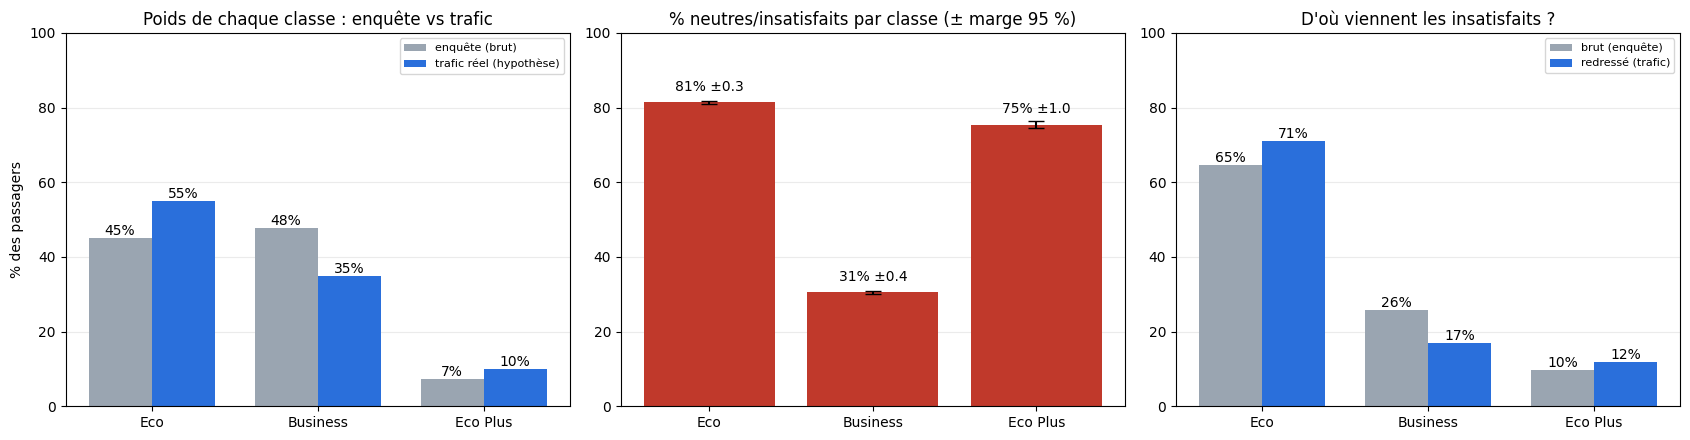

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
x = np.arange(len(CLASSES)); wd = 0.38
COLORS = {"brut": "#9aa5b1", "redressé": "#2a6fdb"}

b1 = axes[0].bar(x - wd / 2, mix["% de l'enquête"], wd, color=COLORS["brut"], label="enquête (brut)")
b2 = axes[0].bar(x + wd / 2, mix["% du trafic réel (hyp.)"], wd, color=COLORS["redressé"], label="trafic réel (hypothèse)")
axes[0].bar_label(b1, fmt="%.0f%%"); axes[0].bar_label(b2, fmt="%.0f%%")
axes[0].set_title("Poids de chaque classe : enquête vs trafic"); axes[0].set_ylabel("% des passagers")

axes[1].bar(x, mix["% neutres/insat."], color="#c0392b", yerr=mix["marge d'erreur 95 % (± pts)"], capsize=6)
for i, (v, e) in enumerate(zip(mix["% neutres/insat."], mix["marge d'erreur 95 % (± pts)"])):
    axes[1].text(i, v + 3, f"{v:.0f}% ±{e:.1f}", ha="center")
axes[1].set_title("% neutres/insatisfaits par classe (± marge 95 %)"); axes[1].set_ylim(0, 100)

b1 = axes[2].bar(x - wd / 2, mix["part des insatisfaits - brut (%)"], wd, color=COLORS["brut"], label="brut (enquête)")
b2 = axes[2].bar(x + wd / 2, mix["part des insatisfaits - redressé (%)"], wd, color=COLORS["redressé"], label="redressé (trafic)")
axes[2].bar_label(b1, fmt="%.0f%%"); axes[2].bar_label(b2, fmt="%.0f%%")
axes[2].set_title("D'où viennent les insatisfaits ?")
for ax in axes:
    ax.set_xticks(x, CLASSES); ax.grid(axis="y", alpha=0.25); ax.set_axisbelow(True)
for ax in (axes[0], axes[2]):
    ax.legend(fontsize=8); ax.set_ylim(0, 100)
fig.tight_layout(); fig.savefig(FIG / "fig0_ecart_sondage.png", dpi=150); plt.show()

**Ce que change le redressement**
- **Le niveau d'insatisfaction réel est plus élevé** : 63,0 % une fois l'enquête remise au mix du trafic, contre 56,7 % en brut. Le chiffre brut est flatté par la Business, sur-interrogée et la plus satisfaite (31 %).
- **Un gros quota de répondants ne fait pas un gros problème** : la Business représente 48 % des répondants, mais seulement **17 % des insatisfaits** du trafic. L'Eco, sous-interrogée (45 %), concentre **71 % des insatisfaits**. L'Eco Plus, la plus petite classe de l'enquête (7 %), pèse 12 % des insatisfaits : plus que sa part dans l'enquête.
- **Précision des mesures** : la marge d'erreur est de ±0,3 à ±0,4 point en Eco et en Business, et de ±1,0 point en Eco Plus (7 468 répondants seulement). Les écarts entre classes (30 à 50 points) sont bien plus grands que ces marges : ils ne sont pas dus au hasard du sondage.
- La taille d'échantillon effective reste de ≈ 97 000 répondants : le redressement coûte peu en précision.
- Les **taux à l'intérieur d'une classe** ne changent pas (le poids est constant dans une classe). Ce qui change, ce sont toutes les **moyennes, parts et classements qui mélangent les classes**.

## 2. Exploration : qui est satisfait, qui ne l'est pas ?

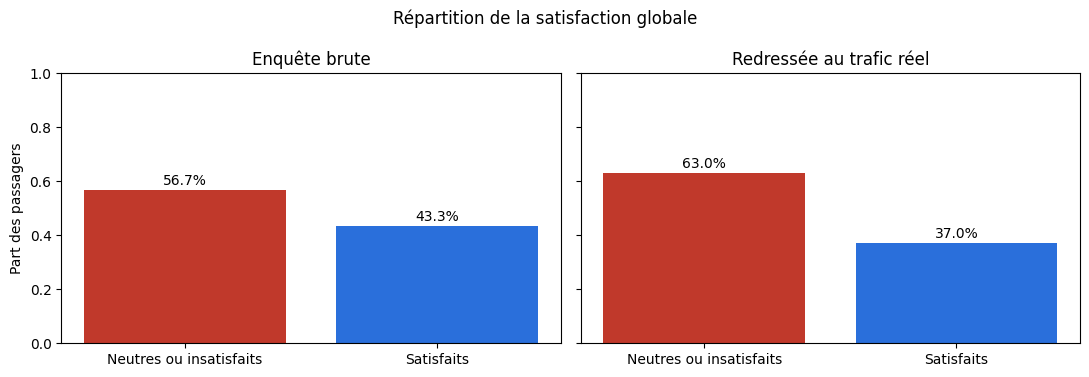

In [6]:
counts = train["satisfaction"].value_counts().loc[["neutral or dissatisfied", "satisfied"]]
w_counts = train.groupby("satisfaction")["w"].sum().loc[counts.index]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, vals, title in [(axes[0], counts / counts.sum(), "Enquête brute"),
                        (axes[1], w_counts / w_counts.sum(), "Redressée au trafic réel")]:
    vals.index = vals.index.map({"neutral or dissatisfied": "Neutres ou insatisfaits", "satisfied": "Satisfaits"})
    ax.bar(vals.index, vals.values, color=["#c0392b", "#2a6fdb"])
    for i, v in enumerate(vals.values):
        ax.text(i, v + 0.01, f"{v:.1%}", ha="center", va="bottom")
    ax.set_ylim(0, 1); ax.set_title(title)
axes[0].set_ylabel("Part des passagers")
fig.suptitle("Répartition de la satisfaction globale")
fig.tight_layout(); fig.savefig(FIG / "fig0b_satisfaction_globale.png", dpi=150); plt.show()

### 2.1 Profil des passagers et taux d'insatisfaction

In [7]:
AGE_BINS = [0, 12, 17, 25, 35, 45, 55, 65, 90]
AGE_LABELS = ["≤12", "13-17", "18-25", "26-35", "36-45", "46-55", "56-65", "66+"]
train["Tranche d'âge"] = pd.cut(train["Age"], AGE_BINS, labels=AGE_LABELS)

rows = []
for col in ["Gender", "Customer Type", "Type of Travel", "Class", "Tranche d'âge"]:
    g = train.groupby(col, observed=True)[TARGET]
    ws, wr = wshare(col), wrate(col)
    for cat, n in g.size().items():
        p = g.mean()[cat]
        rows.append({"variable": col, "catégorie": cat, "répondants": n,
                     "% enquête (brut)": 100 * n / len(train), "% trafic (redressé)": 100 * ws[cat],
                     "% neutres/insat. brut": 100 * p, "% neutres/insat. redressé": 100 * wr[cat],
                     "± marge 95 %": 100 * margin95(p, n)})
profile = pd.DataFrame(rows).set_index(["variable", "catégorie"]).round(1)
profile

répondants  % enquête (brut)  % trafic (redressé)  % neutres/insat. brut  % neutres/insat. redressé  ± marge 95 %
variable       catégorie                                                                                                                           
Gender         Female                  52576              50.8                 50.9                   57.3                       63.6           0.4
               Male                    51018              49.2                 49.1                   56.0                       62.4           0.4
Customer Type  Loyal Customer          84662              81.7                 81.0                   52.3                       59.2           0.3
               disloyal Customer       18932              18.3                 19.0                   76.3                       79.3           0.6
Type of Travel Business travel         71465              69.0                 62.5                   41.7                       46.9           0.4
               Personal Travel         32129              31.0                 37.5                   89.8                       89.9           0.3
Class          Business                49533              47.8                 35.0                   30.6                       30.6           0.4
               Eco                     46593              45.0                 55.0                   81.4                       81.4           0.4
               Eco Plus                 7468               7.2                 10.0                   75.4                       75.4           1.0
Tranche d'âge  ≤12                      3871               3.7                  4.4                   86.5                       87.7           1.1
               13-17                    4030               3.9                  4.5                   80.8                       82.9           1.2
               18-25                   14645              14.1                 15.1                   65.6                       70.2           0.8
               26-35                   18779              18.1                 18.0                   62.4                       67.8           0.7
               36-45                   24494              23.6                 22.4                   48.0                       54.2           0.6
               46-55                   20885              20.2                 18.9                   42.2                       49.5           0.7
               56-65                   12895              12.4                 12.4                   53.6                       60.9           0.9
               66+                      3995               3.9                  4.3                   81.7                       83.5           1.2

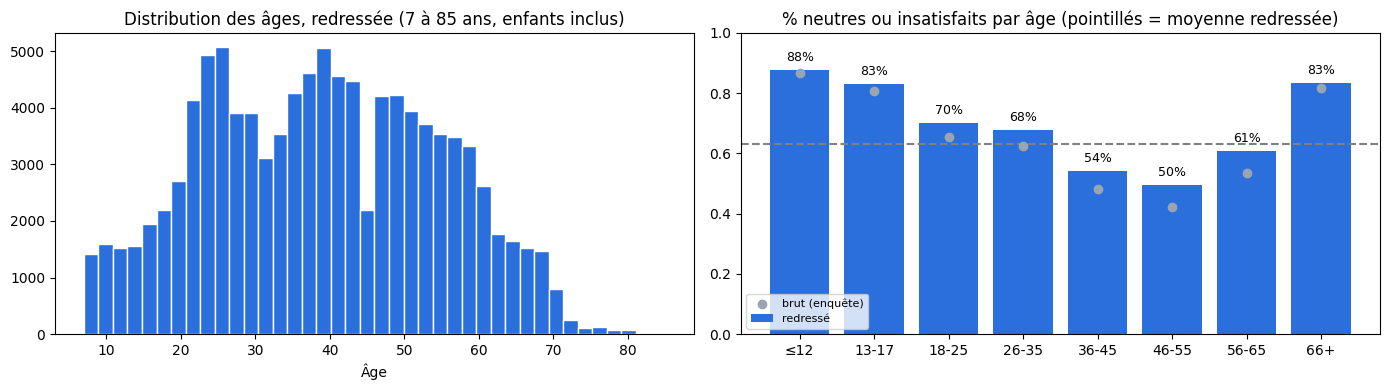

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(train["Age"], bins=40, weights=W, color="#2a6fdb", edgecolor="white")
axes[0].set_title("Distribution des âges, redressée (7 à 85 ans, enfants inclus)"); axes[0].set_xlabel("Âge")
age_rate = wrate("Tranche d'âge")
age_raw = train.groupby("Tranche d'âge", observed=True)[TARGET].mean()
axes[1].bar(age_rate.index.astype(str), age_rate.values, color="#2a6fdb", label="redressé")
axes[1].scatter(age_raw.index.astype(str), age_raw.values, color="#9aa5b1", zorder=3, label="brut (enquête)")
axes[1].axhline(w_rate, ls="--", c="grey")
for i, v in enumerate(age_rate.values):
    axes[1].text(i, v + 0.03, f"{v:.0%}", ha="center", fontsize=9)
axes[1].legend(fontsize=8, loc="lower left")
axes[1].set_ylim(0, 1); axes[1].set_title("% neutres ou insatisfaits par âge (pointillés = moyenne redressée)")
fig.tight_layout(); fig.savefig(FIG / "fig1_age.png", dpi=150); plt.show()

**Lecture** (redressée au trafic, avant de croiser les variables) :
- **Type de voyage** : 90 % de neutres ou insatisfaits en voyage personnel, contre 47 % en voyage professionnel (42 % en brut). Le voyage personnel pèse 37,5 % du trafic, contre 31 % de l'enquête.
- **Classe** : Eco 81 %, Eco Plus 75 %, Business 31 %. Ces taux sont les mêmes en brut et en redressé ; c'est le **poids** des classes qui change (Eco 55 %, Business 35 %, Eco Plus 10 % du trafic).
- **Fidélité** : 79 % chez les non fidèles, contre 59 % chez les fidèles (52 % en brut).
- **Âge** : courbe en U, avec les enfants (88 %) et les seniors (84 %) les plus insatisfaits ; tous les âges montent de 2 à 7 points une fois redressés.
- **Genre** : 64 % contre 62 %, aucun écart utile.

Ces écarts peuvent encore être **trompeurs** : les groupes diffèrent sur plusieurs dimensions à la fois. On les croise en 2.3.

### 2.2 Distance du vol

In [9]:
dist_bins = pd.cut(train["Flight Distance"], [0, 500, 1000, 1500, 2000, 3000, 6000],
                   labels=["≤500", "501-1000", "1001-1500", "1501-2000", "2001-3000", "3000+"])
dist = pd.DataFrame({
    "répondants": train.groupby(dist_bins, observed=True).size(),
    "% du trafic (redressé)": 100 * wshare(dist_bins),
    "% neutres/insatisfaits": 100 * wrate(dist_bins),
    "% neutres/insat. brut": 100 * train.groupby(dist_bins, observed=True)[TARGET].mean(),
    "% en Business": 100 * wrate(dist_bins, data=train.assign(_bus=(train["Class"] == "Business").astype(int)), col="_bus"),
}).round(1)
dist

,répondants,% du trafic (redressé),% neutres/insatisfaits,% neutres/insat. brut,% en Business
Flight Distance,,,,,
≤500,32237,33.8,70.4,66.7,21.1
501-1000,27665,29.0,71.9,67.5,20.9
1001-1500,12319,12.5,69.1,63.7,26.2
1501-2000,10028,8.4,49.0,41.9,61.2
2001-3000,13097,10.4,40.7,35.3,72.7
3000+,8248,5.9,22.9,22.6,98.8


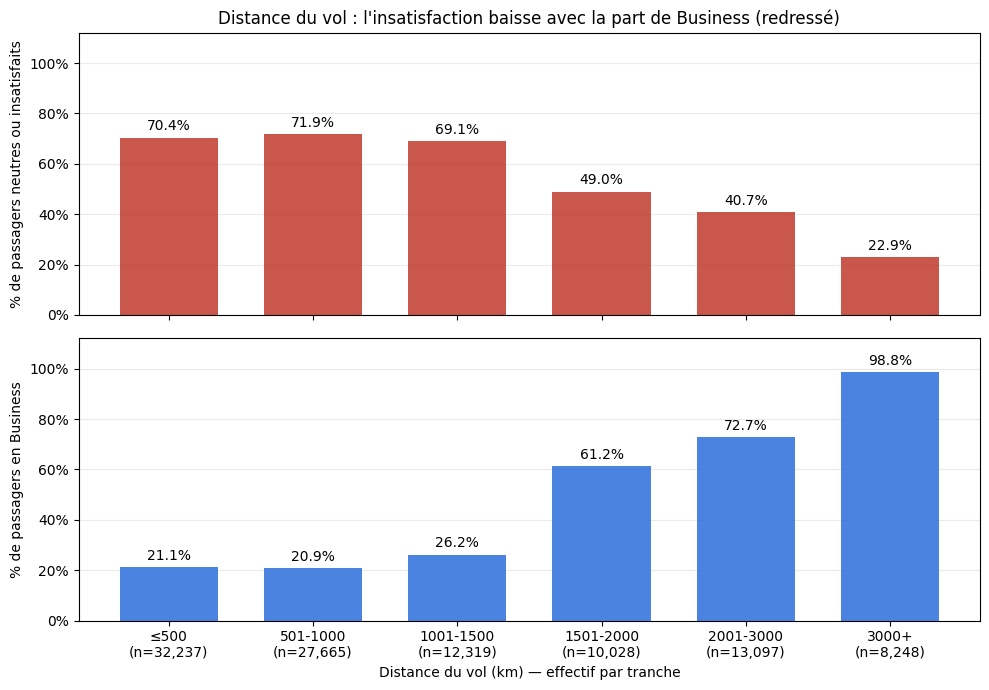

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
x = np.arange(len(dist))
series = [
    ("% neutres/insatisfaits", "% de passagers neutres ou insatisfaits", "#c0392b"),
    ("% en Business", "% de passagers en Business", "#2a6fdb"),
]
for ax, (column, ylabel, color) in zip(axes, series):
    values = dist[column].to_numpy()
    bars = ax.bar(x, values, color=color, alpha=0.85, width=0.68)
    ax.bar_label(bars, labels=[f"{value:.1f}%" for value in values], padding=3)
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, 112)
    ax.set_yticks(np.arange(0, 101, 20), labels=[f"{value}%" for value in range(0, 101, 20)])
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

axes[0].set_title("Distance du vol : l'insatisfaction baisse avec la part de Business (redressé)")
axes[-1].set_xticks(x, [f"{label}\n(n={count:,})" for label, count in zip(dist.index, dist["répondants"])])
axes[-1].set_xlabel("Distance du vol (km) — effectif par tranche")
fig.tight_layout()
fig.savefig(FIG / "fig_distance.png", dpi=150, bbox_inches="tight")
plt.show()

L'insatisfaction redressée chute au-delà de 1 500 km (de ≈ 70 % à 23 %). Mais la part de Business monte en même temps, de 21 % à 99 %. **À l'intérieur de chaque classe, la distance ne fait presque rien** (graphique suivant) : en Eco, l'insatisfaction **monte** même légèrement avec la distance (79 % → 90 %), alors qu'en Business elle baisse (41 % → 22 %). La distance est donc surtout un **indicateur de la classe**.

,distance_vol (brut)
count,103594.0
mean,1189.3
std,997.3
min,31.0
10%,236.0
25%,414.0
50%,842.0
75%,1743.0
90%,2751.0
max,4983.0


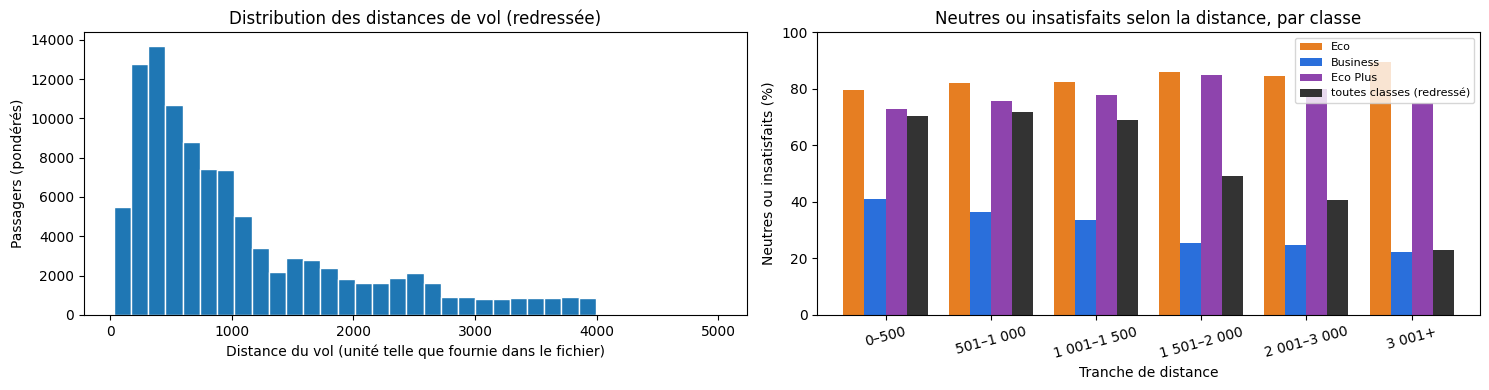

Class,Eco,Business,Eco Plus,toutes classes (redressé)
Flight Distance,,,,
0–500,79.4,40.9,72.7,70.4
501–1 000,82.2,36.6,75.6,71.9
1 001–1 500,82.3,33.6,78.0,69.1
1 501–2 000,86.0,25.6,85.0,49.0
2 001–3 000,84.5,24.6,80.0,40.7
3 001+,89.6,22.1,75.0,22.9


In [11]:
# Distance des vols : distribution et statistiques descriptives (redressées)
distance = train["Flight Distance"]
display(distance.describe(percentiles=[.10, .25, .50, .75, .90]).to_frame("distance_vol (brut)").round(1))

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
axes[0].hist(distance, bins=35, weights=W, edgecolor="white")
axes[0].set_title("Distribution des distances de vol (redressée)")
axes[0].set_xlabel("Distance du vol (unité telle que fournie dans le fichier)")
axes[0].set_ylabel("Passagers (pondérés)")

# Tranches indicatives pour rendre les comparaisons lisibles, par classe
distance_bins = [0, 500, 1000, 1500, 2000, 3000, np.inf]
distance_labels = ["0–500", "501–1 000", "1 001–1 500", "1 501–2 000", "2 001–3 000", "3 001+"]
tr_dist = pd.cut(train["Flight Distance"], bins=distance_bins, labels=distance_labels, include_lowest=True)
by_cls = (100 * pd.crosstab(tr_dist, train["Class"], values=train[TARGET], aggfunc="mean"))[CLASSES]
by_cls["toutes classes (redressé)"] = 100 * wrate(tr_dist)
by_cls.plot(kind="bar", ax=axes[1], color=["#e67e22", "#2a6fdb", "#8e44ad", "#333333"], width=0.8)
axes[1].set_title("Neutres ou insatisfaits selon la distance, par classe")
axes[1].set_xlabel("Tranche de distance"); axes[1].set_ylabel("Neutres ou insatisfaits (%)")
axes[1].set_ylim(0, 100); axes[1].legend(fontsize=8); axes[1].tick_params(axis="x", rotation=15)
fig.tight_layout(); fig.savefig(FIG / "fig_distance_detail.png", dpi=150); plt.show()
by_cls.round(1)

### 2.3 Croisements : éviter les conclusions trop rapides
On regarde si chaque effet brut **tient encore à l'intérieur d'un même segment** (type de voyage × classe). Si l'effet disparaît, c'était un effet de composition.

In [12]:
segment = train["Type of Travel"] + " | " + train["Class"]
print("Taux d'insatisfaction par segment (type de voyage x classe x fidélité) :")
seg = pd.crosstab([train["Type of Travel"], train["Class"]], train["Customer Type"],
                  values=train[TARGET], aggfunc="mean").round(2)
share_raw = pd.crosstab([train["Type of Travel"], train["Class"]], train["Customer Type"], normalize=True).round(3)
share_w = pd.crosstab([train["Type of Travel"], train["Class"]], train["Customer Type"],
                      values=train["w"], aggfunc="sum", normalize=True).round(3)
print(seg.to_string(), "\n\nPart des passagers - enquête brute :\n", share_raw.to_string(),
      "\n\nPart des passagers - trafic redressé :\n", share_w.to_string())

Taux d'insatisfaction par segment (type de voyage x classe x fidélité) :
Customer Type             Loyal Customer  disloyal Customer
Type of Travel  Class                                      
Business travel Business            0.22               0.60
                Eco                 0.53               0.86
                Eco Plus            0.54               0.92
Personal Travel Business            0.88               1.00
                Eco                 0.90               0.83
                Eco Plus            0.91               1.00 

Part des passagers - enquête brute :
 Customer Type             Loyal Customer  disloyal Customer
Type of Travel  Class                                      
Business travel Business           0.387              0.071
                Eco                0.091              0.104
                Eco Plus           0.031              0.007
Personal Travel Business           0.021              0.000
                Eco                0.253       

In [13]:
age3 = pd.cut(train["Age"], [0, 12, 17, 25, 40, 60, 90], labels=["≤12", "13-17", "18-25", "26-40", "41-60", "60+"])
print("Âge : composition (% en voyage perso, redressé) et insatisfaction PAR type de voyage")
age_cross = pd.DataFrame({
    "% voyage perso": 100 * wrate(age3, data=train.assign(_p=(train["Type of Travel"] == "Personal Travel").astype(int)), col="_p"),
    "insat. voyage pro": 100 * wrate([age3, train["Type of Travel"]]).unstack()["Business travel"],
    "insat. voyage perso": 100 * wrate([age3, train["Type of Travel"]]).unstack()["Personal Travel"],
}).round(1)
print(age_cross.to_string())

print("\nDistance : insatisfaction à l'intérieur du segment 'voyage pro | Business'")
m = segment == "Business travel | Business"
print((100 * train[m].groupby(dist_bins[m], observed=True)[TARGET].mean()).round(1).to_string())

print("\nGenre : insatisfaction par segment")
print((100 * pd.crosstab(train["Gender"], segment, values=train[TARGET], aggfunc="mean")).round(1).to_string())

Âge : composition (% en voyage perso, redressé) et insatisfaction PAR type de voyage
       % voyage perso  insat. voyage pro  insat. voyage perso
Age                                                          
≤12              80.3               79.8                 89.6
13-17            69.3               68.1                 89.4
18-25            30.7               61.3                 90.2
26-40            29.9               53.7                 89.7
41-60            30.8               31.8                 90.0
60+              67.1               63.5                 90.4

Distance : insatisfaction à l'intérieur du segment 'voyage pro | Business'
Flight Distance
≤500         36.7
501-1000     31.9
1001-1500    29.4
1501-2000    24.4
2001-3000    23.9
3000+        22.1

Genre : insatisfaction par segment
col_0   Business travel | Business  Business travel | Eco  Business travel | Eco Plus  Personal Travel | Business  Personal Travel | Eco  Personal Travel | Eco Plus
Gender            

**Ce que les croisements changent**
- **Âge** : 80 % des enfants de 12 ans ou moins voyagent pour motif personnel (trafic redressé), contre 31 % des 41-60 ans. **En voyage personnel, l'âge ne change rien** : ≈ 90 % d'insatisfaits à tous les âges. L'effet d'âge n'existe qu'en voyage professionnel (80 % chez les enfants, 32 % chez les 41-60 ans). Le chiffre brut « 88 % des enfants insatisfaits » s'explique donc **surtout par le motif du voyage**, pas par l'âge.
- **Distance** : à l'intérieur du segment pro Business, l'effet est faible (de 37 % à 22 %). La distance reflète surtout la classe.
- **Genre** : moins de 2 points d'écart dans presque tous les segments. Seul le petit segment pro en Eco Plus montre 6 points. Aucun effet exploitable : le genre est écarté.
- **Les segments dominent, mais pas là où l'enquête le laisse croire** : le segment pro Business fidèle pèse 39 % des répondants mais **28 % du trafic** (22 % d'insatisfaits). Le segment **loisirs en Eco**, lui, pèse 25 % des répondants mais **31 % du trafic**, avec 90 % d'insatisfaits : c'est le **premier réservoir d'insatisfaits**.

### 2.4 Retards : effet sur la satisfaction et sur les notes
Un passager retardé est-il insatisfait **parce qu'il note mal les services**, ou **alors que ses notes restent bonnes** ? La cible regroupe « neutre » et « insatisfait », donc on distingue les passagers par leur **profil de notes** : bonnes (moyenne ≥ 4), moyennes (3 à 4) ou mauvaises (< 3).

In [14]:
def delay_bucket(s):
    return pd.cut(s, [-1, 0, 15, 30, 60, 120, 2000],
                  labels=["0", "1-15", "16-30", "31-60", "61-120", ">120"])

rows = {}
for col in ["Departure Delay in Minutes", "Arrival Delay in Minutes"]:
    rows[col] = (100 * wrate(delay_bucket(train[col]))).round(1)
delays = pd.DataFrame(rows)
delays["% du trafic (arrivée, redressé)"] = (100 * wshare(delay_bucket(train["Arrival Delay in Minutes"]))).round(1)
print("% neutres ou insatisfaits selon le retard (min), redressé :")
delays

% neutres ou insatisfaits selon le retard (min), redressé :


,Departure Delay in Minutes,Arrival Delay in Minutes,"% du trafic (arrivée, redressé)"
0,60.4,59.1,55.9
1-15,63.0,65.1,21.0
16-30,68.5,70.9,8.7
31-60,70.2,70.8,7.1
61-120,70.4,70.7,4.6
>120,69.9,69.3,2.6


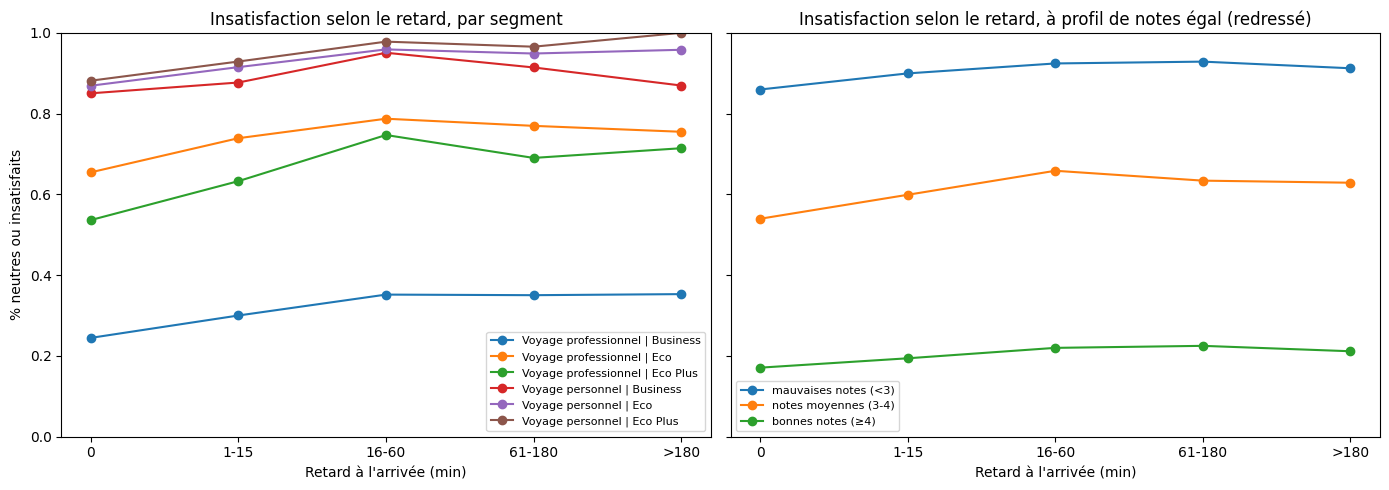

Arrival Delay in Minutes     0  1-15  16-60  61-180  >180
mauvaises notes (<3)      86.0  90.0   92.4    92.9  91.2
notes moyennes (3-4)      54.0  59.9   65.8    63.4  62.9
bonnes notes (≥4)         17.1  19.4   22.0    22.5  21.2


In [15]:
delay5 = pd.cut(train["Arrival Delay in Minutes"], [-1, 0, 15, 60, 180, 2000],
                labels=["0", "1-15", "16-60", "61-180", ">180"])
mean_note = train[SERVICES].mean(axis=1)
note_profile = pd.cut(mean_note, [0, 3, 4, 5.01], right=False,
                      labels=["mauvaises notes (<3)", "notes moyennes (3-4)", "bonnes notes (≥4)"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
seg_rates = pd.crosstab(segment, delay5, values=train[TARGET], aggfunc="mean")  # 1 segment = 1 classe : poids constant
for name, row in seg_rates.iterrows():
    label = name.replace("Business travel", "Voyage professionnel").replace("Personal Travel", "Voyage personnel")
    axes[0].plot(row.index.astype(str), row.values, marker="o", label=label)
axes[0].set_title("Insatisfaction selon le retard, par segment"); axes[0].legend(fontsize=8)
axes[0].set_ylabel("% neutres ou insatisfaits")
prof_rates = wrate([note_profile, delay5]).unstack()
for name, row in prof_rates.iterrows():
    axes[1].plot(row.index.astype(str), row.values, marker="o", label=name)
axes[1].set_title("Insatisfaction selon le retard, à profil de notes égal (redressé)"); axes[1].legend(fontsize=8)
for ax in axes:
    ax.set_xlabel("Retard à l'arrivée (min)"); ax.set_ylim(0, 1)
fig.tight_layout(); fig.savefig(FIG / "fig2_retards.png", dpi=150); plt.show()

print((100 * prof_rates).round(1).to_string())

In [16]:
note_by_delay = (train[SERVICES].mul(train["w"], axis=0).groupby(delay5, observed=True).sum()
                 .div(train[SERVICES].notna().mul(train["w"], axis=0).groupby(delay5, observed=True).sum()))
print("Note moyenne de tous les services, par retard (redressé) :", note_by_delay.mean(axis=1).round(2).to_dict())
same_notes = wrate([delay5, train[TARGET]], data=train.assign(_note=mean_note), col="_note").unstack().round(2)
same_notes.columns = ["note moy. des satisfaits", "note moy. des neutres/insatisfaits"]
print(same_notes.to_string())

late = train["Departure Delay in Minutes"] > 30
caught_up = train["Arrival Delay in Minutes"] < train["Departure Delay in Minutes"]
print(f"\nPartis avec plus de 30 min de retard - retard rattrapé en vol : {np.average(train[TARGET][late & caught_up], weights=train['w'][late & caught_up]):.1%} | "
      f"non rattrapé : {np.average(train[TARGET][late & ~caught_up], weights=train['w'][late & ~caught_up]):.1%}")

Note moyenne de tous les services, par retard (redressé) : {'0': 3.26, '1-15': 3.21, '16-60': 3.17, '61-180': 3.16, '>180': 3.15}
                          note moy. des satisfaits  note moy. des neutres/insatisfaits
Arrival Delay in Minutes                                                              
0                                             3.63                                3.01
1-15                                          3.66                                2.98
16-60                                         3.68                                2.96
61-180                                        3.65                                2.95
>180                                          3.62                                2.95

Partis avec plus de 30 min de retard - retard rattrapé en vol : 70.3% | non rattrapé : 70.0%


**À retenir sur les retards** (trafic redressé)
1. **Effet de seuil** : 59 % d'insatisfaits à l'heure, 65 % entre 1 et 15 min, environ 71 % dès 16 min de retard, puis plus de hausse, même au-delà de 2 h.
2. **L'effet existe dans tous les segments**, donc dans toutes les classes : ce n'est pas un effet de profil.
3. **Les notes de service bougent à peine** (3,26 → 3,15). Un satisfait et un insatisfait notent pareil, retard ou pas. Le retard agit **directement** sur la satisfaction globale, sans « contaminer » les notes.
4. **Bonnes notes quand même** : chez les passagers qui notent bien (≥ 4), la part de neutres ou insatisfaits passe de 17 % à 21-22 %. Chez ceux qui donnent des notes moyennes, elle passe de 54 % à 63-66 % : ce sont les passagers « hésitants » que le retard fait basculer.
5. **Rattraper le retard en vol ne change rien** (≈ 70 % dans les deux cas). C'est aussi la **limite** relevée en 1 : le retard au départ et le retard à l'arrivée divergent parfois, et c'est le retard **à l'arrivée** qui compte.
6. Le retard est **connu à l'atterrissage** : c'est une variable utilisable par le modèle, et un motif simple à montrer à un agent.

## 3. Facteurs de satisfaction : quels leviers financer ?

### 3.1 Lien de chaque service avec la satisfaction, classe par classe
Pour que la Business, sur-représentée dans l'enquête, n'impose pas ses priorités, le lien est calculé **à l'intérieur de chaque classe**, puis combiné selon le poids de la classe dans le **trafic réel**. On affiche aussi le lien brut (enquête non redressée), le lien « classes à égalité » (chaque classe compte pour 1/3, quelle que soit sa taille) et le rang de chaque service dans les trois cas.

In [17]:
rows = {}
for c in SERVICES:
    x = train[c]
    r = {"lien brut (enquête)": -x.corr(train[TARGET], method="spearman")}
    for k in CLASSES:
        m = train["Class"] == k
        r[f"lien {k}"] = -x[m].corr(train[TARGET][m], method="spearman")
    r["lien redressé"] = sum(CLASS_MIX_REEL[k] * r[f"lien {k}"] for k in CLASSES)
    r["lien classes à égalité"] = sum(MIX_EGAL[k] * r[f"lien {k}"] for k in CLASSES)
    for s, name in [("Business travel | Business", "pro Business"),
                    ("Business travel | Eco", "pro Eco"),
                    ("Personal Travel | Eco", "perso Eco")]:
        m = segment == s
        r[name] = -x[m].corr(train[TARGET][m], method="spearman")
    ok = x.notna()
    r["note moyenne"] = np.average(x[ok], weights=W[ok])
    r["% notes ≤2"] = 100 * np.average((x[ok] <= 2), weights=W[ok])
    rows[c] = r
drivers = pd.DataFrame(rows).T
drivers["rang brut"] = drivers["lien brut (enquête)"].rank(ascending=False).astype(int)
drivers["rang redressé"] = drivers["lien redressé"].rank(ascending=False).astype(int)
drivers["rang classes à égalité"] = drivers["lien classes à égalité"].rank(ascending=False).astype(int)
drivers = drivers.sort_values("lien redressé", ascending=False).round(2)
drivers

,lien brut (enquête),lien Eco,lien Business,lien Eco Plus,lien redressé,lien classes à égalité,pro Business,pro Eco,perso Eco,note moyenne,% notes ≤2,rang brut,rang redressé,rang classes à égalité
Online boarding,0.59,0.42,0.57,0.47,0.48,0.49,0.59,0.54,0.32,3.22,30.64,1,1,2
Inflight wifi service,0.37,0.58,0.25,0.64,0.47,0.49,0.24,0.67,0.46,2.80,43.56,3,2,1
Inflight entertainment,0.40,0.18,0.49,0.33,0.31,0.34,0.50,0.36,-0.00,3.29,30.92,2,3,3
Seat comfort,0.36,0.12,0.45,0.23,0.25,0.27,0.47,0.26,0.00,3.36,28.16,4,4,4
Ease of Online booking,0.23,0.32,0.12,0.21,0.24,0.22,0.10,0.24,0.42,2.84,42.68,10,5,6
Cleanliness,0.30,0.14,0.39,0.26,0.24,0.26,0.40,0.27,0.00,3.24,30.20,7,6,5
On-board service,0.33,0.08,0.42,0.08,0.20,0.19,0.43,0.21,-0.00,3.31,27.51,5,7,8
Leg room service,0.32,0.08,0.42,0.07,0.20,0.19,0.41,0.10,0.07,3.30,30.81,6,8,9
Food and drink,0.21,0.14,0.22,0.26,0.18,0.21,0.23,0.27,0.01,3.18,34.37,12,9,7
Baggage handling,0.27,0.03,0.38,-0.00,0.15,0.13,0.39,0.11,0.00,3.58,19.02,8,10,10


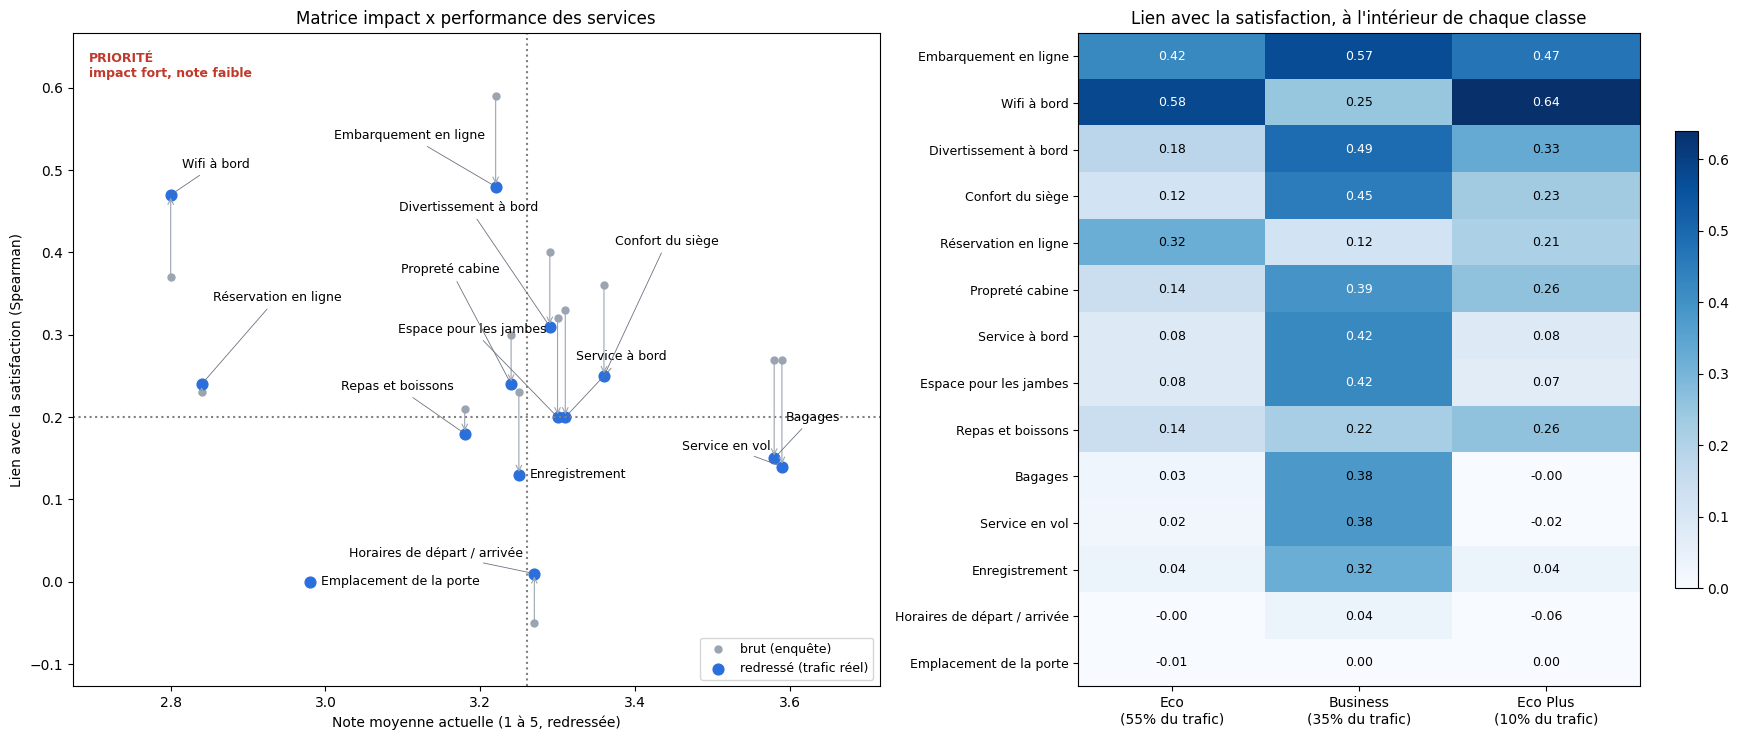

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7.5), gridspec_kw={"width_ratios": [1.15, 1]})
ax = axes[0]
for name, r in drivers.iterrows():
    ax.annotate("", xy=(r["note moyenne"], r["lien redressé"]), xytext=(r["note moyenne"], r["lien brut (enquête)"]),
                arrowprops=dict(arrowstyle="->", color="#9aa5b1", lw=0.8))
ax.scatter(drivers["note moyenne"], drivers["lien brut (enquête)"], s=25, color="#9aa5b1", label="brut (enquête)")
ax.scatter(drivers["note moyenne"], drivers["lien redressé"], s=60, color="#2a6fdb", label="redressé (trafic réel)")
ax.margins(x=0.16, y=0.12)
fig.canvas.draw()
label_points = []
for name, r in drivers.iterrows():
    point_y = ax.transData.transform((r["note moyenne"], r["lien redressé"]))[1]
    label_points.append((point_y, name, r))
label_points.sort(key=lambda item: item[0])
min_gap = 20 * fig.dpi / 72
bottom, top = ax.bbox.y0 + 6, ax.bbox.y1 - 38
label_ys = [min(max(point_y, bottom), top) for point_y, _, _ in label_points]
for i in range(1, len(label_ys)):
    label_ys[i] = max(label_ys[i], label_ys[i - 1] + min_gap)
overflow = max(0, label_ys[-1] - top)
label_ys = [y - overflow for y in label_ys]
for i, ((point_y, name, r), label_y) in enumerate(zip(label_points, label_ys)):
    side = 1 if i % 2 == 0 else -1
    ax.annotate(SERVICE_LABELS_FR.get(name, name), (r["note moyenne"], r["lien redressé"]),
                xytext=(side * 8, (label_y - point_y) * 72 / fig.dpi),
                textcoords="offset points", ha="left" if side > 0 else "right", va="center",
                fontsize=9, arrowprops=dict(arrowstyle="-", color="#6b7280", lw=0.6, shrinkA=2, shrinkB=3))
ax.axvline(drivers["note moyenne"].median(), ls=":", c="grey")
ax.axhline(drivers["lien redressé"].median(), ls=":", c="grey")
ax.text(0.02, 0.97, "PRIORITÉ\nimpact fort, note faible", transform=ax.transAxes, va="top",
        fontsize=9, color="#c0392b", weight="bold", bbox=dict(facecolor="white", alpha=0.85, edgecolor="none", pad=3))
ax.set_xlabel("Note moyenne actuelle (1 à 5, redressée)"); ax.set_ylabel("Lien avec la satisfaction (Spearman)")
ax.set_title("Matrice impact x performance des services"); ax.legend(fontsize=9, loc="lower right")

heat = drivers[[f"lien {k}" for k in CLASSES]]
im = axes[1].imshow(heat.values, cmap="Blues", aspect="auto", vmin=0, vmax=heat.values.max())
axes[1].set_xticks(range(3), [f"{k}\n({CLASS_MIX_REEL[k]:.0%} du trafic)" for k in CLASSES])
axes[1].set_yticks(range(len(heat)), [SERVICE_LABELS_FR.get(name, name) for name in heat.index], fontsize=9)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        axes[1].text(j, i, f"{heat.values[i, j]:.2f}", ha="center", va="center", fontsize=9,
                     color="white" if heat.values[i, j] > 0.6 * heat.values.max() else "black")
axes[1].set_title("Lien avec la satisfaction, à l'intérieur de chaque classe")
fig.colorbar(im, ax=axes[1], shrink=0.7)
fig.tight_layout(); fig.savefig(FIG / "fig3_matrice_services.png", dpi=150, bbox_inches="tight"); plt.show()

*Lecture* : le « lien » est la corrélation de Spearman entre la note et le fait d'être satisfait, **calculée à l'intérieur de chaque classe** puis combinée selon le trafic réel. Les flèches du graphique montrent le déplacement entre le calcul brut (gris) et le calcul redressé (bleu).

**Le redressement change le classement des priorités** :
- **Embarquement en ligne** : reste n°1, fort dans les trois classes (0,42 à 0,57).
- **Wifi** : passe du 3e au **2e rang** (0,37 → 0,47). Il est **le premier levier en Eco (0,58) et en Eco Plus (0,64)**, mais faible en Business (0,25). L'enquête brute le sous-estimait parce qu'elle sur-représente la Business.
- **Réservation en ligne** : passe du **10e au 5e rang**, portée par l'Eco et le voyage de loisirs (0,42).
- **Confort cabine** (divertissement, siège, service à bord, jambes, bagages) : **perd plusieurs rangs**. Il ne compte vraiment qu'en Business (0,38 à 0,49), et quasiment pas en Eco (≤ 0,18). Son importance brute venait du poids excessif de la Business dans l'enquête.

C'est exactement le piège évité : les services qui comptent pour le groupe le plus interrogé (la Business) ne sont pas ceux qui comptent pour le plus grand nombre de passagers réels.

**Lecture « classes à égalité »** (chaque classe compte pour 1/3, quelle que soit sa taille) : le **wifi passe n°1** (0,49), devant l'embarquement en ligne (0,49) et le divertissement (0,34). Le top 4 est le même qu'en lecture redressée ; seuls les rangs 5 à 9 bougent un peu (propreté et restauration gagnent une place, grâce à l'Eco Plus). **Quelle que soit la façon de neutraliser la taille des groupes, embarquement en ligne et wifi restent les deux priorités.**

### 3.2 Effet de chaque service *à profil égal* (modèle explicatif)
Régression logistique sur toutes les notes et le profil du passager, **entraînée avec les poids de redressement**. Elle donne l'effet d'un point de note en plus sur les chances d'être satisfait, à profil identique. Ce modèle sert à **expliquer**, pas à prédire à l'atterrissage : il utilise les réponses au questionnaire.

In [19]:
expl_cat = ["Customer Type", "Type of Travel", "Class"]
expl_profile = ["Age", "Flight Distance", "Arrival Delay in Minutes"]
expl_pre = ColumnTransformer([
    ("cat", OneHotEncoder(drop="first"), expl_cat),
    ("svc", SimpleImputer(strategy="median", add_indicator=True), SERVICES),  # notes laissées en points
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), expl_profile),
])
explainer = make_pipeline(expl_pre, LogisticRegression(max_iter=5000))
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
Xe = train[expl_cat + SERVICES + expl_profile]
aucs = []
for tr, te in cv.split(train, train[TARGET]):
    fit_w(explainer, Xe.iloc[tr], train[TARGET].iloc[tr], W[tr])
    p = explainer.predict_proba(Xe.iloc[te])[:, 1]
    aucs.append(roc_auc_score(train[TARGET].iloc[te], p, sample_weight=W[te]))
print(f"AUC du modèle explicatif (validation croisée, redressée) : {np.mean(aucs):.3f} ± {np.std(aucs):.3f}")

fit_w(explainer, Xe, train[TARGET], W)
names = [n.split("__", 1)[1] for n in explainer[0].get_feature_names_out()]
coefs = pd.Series(explainer[-1].coef_[0], index=names)
odds = np.exp(-coefs[SERVICES]).sort_values(ascending=False).round(2)
odds.name = "x chances d'être satisfait par point de note"
odds.to_frame()

AUC du modèle explicatif (validation croisée, redressée) : 0.964 ± 0.001


,x chances d'être satisfait par point de note
Inflight wifi service,2.67
Online boarding,2.42
Ease of Online booking,1.46
Checkin service,1.38
On-board service,1.38
Leg room service,1.30
Cleanliness,1.23
Inflight service,1.14
Baggage handling,1.13
Inflight entertainment,1.10


À profil égal et sur le trafic redressé, **le wifi (≈ ×2,7) et l'embarquement en ligne (≈ ×2,4)** restent les deux leviers dominants, devant la réservation en ligne (×1,5). Le wifi passe devant l'embarquement, alors qu'il était derrière avec l'enquête brute : c'est l'effet du poids de l'Eco. Le divertissement et le siège tombent à environ ×1, et la porte et l'horaire passent sous 1. Ce n'est pas un vrai effet : ces notes sont très corrélées entre elles (environ 0,6-0,7), et le modèle répartit l'effet entre elles de façon instable. Il ne faut donc pas conclure qu'« améliorer la porte d'embarquement réduit la satisfaction ».

### 3.3 À l'inverse : qu'est-ce qui rend un passager **satisfait** ?
Éviter les mauvaises notes et obtenir de l'excellence sont deux choses différentes. Pour chaque service, on mesure :
- la **pénalité** : combien d'insatisfaits en plus quand la note passe de 3 à 1-2 ;
- le **bonus** : combien d'insatisfaits en moins quand la note passe de 3 à 5.

Inspiré du modèle de Kano :
- **service de base** : pénalité forte, bonus faible (il doit juste ne pas décevoir) ;
- **service d'excellence** : bonus fort (c'est lui qui rend vraiment satisfait).

In [20]:
rows = {}
for c in SERVICES:
    x = train[c]
    r = {f"insat. si {k}": winsat(m) for k, m in [("1-2", x <= 2), ("3", x == 3), ("4", x == 4), ("5", x == 5)]}
    r["pénalité (3 -> 1-2)"] = r["insat. si 1-2"] - r["insat. si 3"]
    r["bonus (3 -> 5)"] = r["insat. si 3"] - r["insat. si 5"]
    for k in CLASSES:
        mk = train["Class"] == k
        r[f"bonus {k}"] = train.loc[mk & (x == 3), TARGET].mean() - train.loc[mk & (x == 5), TARGET].mean()
    sat, ins = train[TARGET] == 0, train[TARGET] == 1
    r["% satisfaits notant 4-5"] = np.average(x[sat] >= 4, weights=W[sat])
    r["% insatisfaits notant 4-5"] = np.average(x[ins] >= 4, weights=W[ins])
    rows[c] = r
kano = pd.DataFrame(rows).T.sort_values("bonus (3 -> 5)", ascending=False).round(2)
kano.to_csv(FIG / "kano_services.csv")
kano

,insat. si 1-2,insat. si 3,insat. si 4,insat. si 5,pénalité (3 -> 1-2),bonus (3 -> 5),bonus Eco,bonus Business,bonus Eco Plus,% satisfaits notant 4-5,% insatisfaits notant 4-5
Inflight wifi service,0.79,0.81,0.44,0.01,-0.02,0.80,0.97,0.43,0.94,0.56,0.14
Online boarding,0.90,0.89,0.44,0.17,0.01,0.72,0.55,0.69,0.64,0.81,0.24
Ease of Online booking,0.73,0.75,0.52,0.29,-0.02,0.47,0.56,0.18,0.39,0.47,0.21
Seat comfort,0.80,0.81,0.51,0.43,-0.00,0.37,0.11,0.60,0.23,0.75,0.40
Inflight entertainment,0.84,0.77,0.46,0.43,0.07,0.34,0.15,0.43,0.32,0.75,0.35
Baggage handling,0.72,0.80,0.60,0.47,-0.08,0.33,0.11,0.44,0.18,0.74,0.52
Inflight service,0.72,0.79,0.60,0.47,-0.07,0.32,0.11,0.43,0.14,0.74,0.52
Leg room service,0.78,0.76,0.50,0.47,0.01,0.30,0.09,0.41,0.13,0.68,0.37
On-board service,0.79,0.73,0.54,0.44,0.06,0.29,0.10,0.35,0.16,0.68,0.39
Gate location,0.59,0.71,0.67,0.49,-0.12,0.23,0.13,0.09,0.18,0.38,0.35


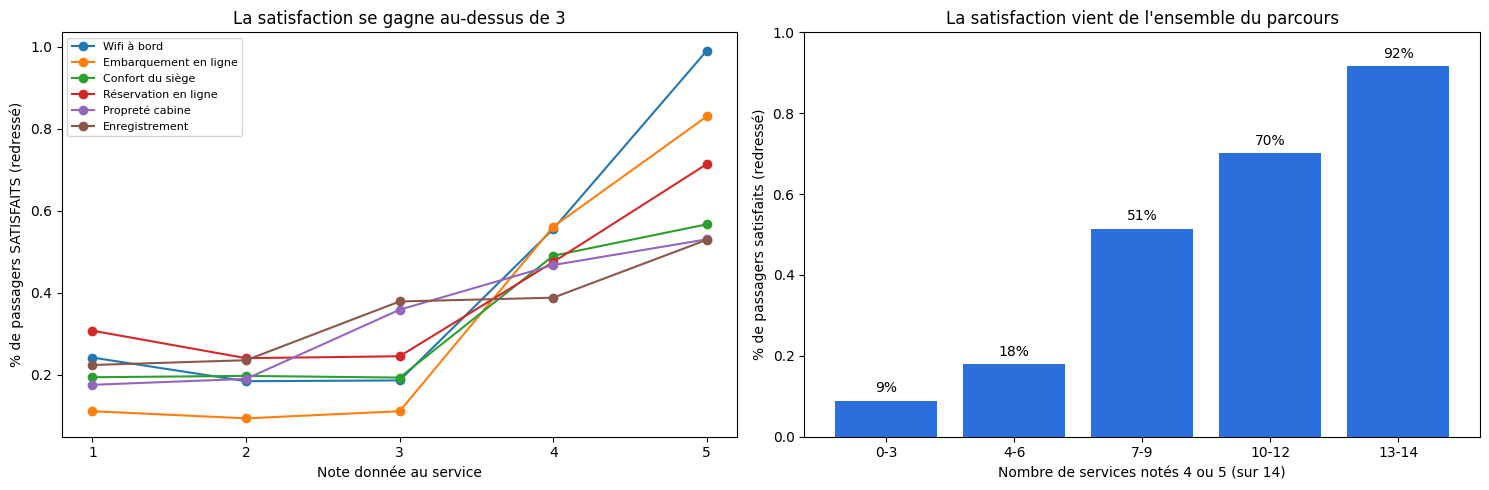

Segment le plus satisfait (pro, Business, fidèle) : 78% de satisfaits, 39% des répondants mais seulement 28% du trafic redressé
Notes moyennes, satisfaits vs neutres/insatisfaits, dans CE segment :
dissatisfied            satisfaits  neutres/insat.  écart
Inflight entertainment        4.15            2.43   1.72
On-board service              4.05            2.48   1.57
Leg room service              4.04            2.62   1.42
Baggage handling              4.11            2.70   1.42
Cleanliness                   3.88            2.47   1.41
Inflight service              4.11            2.70   1.41

Segment le plus insatisfait en volume (perso, Eco) : 90% d'insatisfaits, 25% des répondants -> 31% du trafic redressé
Notes moyennes, satisfaits vs neutres/insatisfaits, dans CE segment :
dissatisfied            satisfaits  neutres/insat.  écart
Inflight wifi service         4.50            2.40   2.10
Ease of Online booking        4.35            2.46   1.88
Online boarding               4.1

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
top = ["Inflight wifi service", "Online boarding", "Seat comfort", "Ease of Online booking", "Cleanliness", "Checkin service"]
for c in top:
    rate = 1 - wrate(train[c])
    axes[0].plot(rate.index, rate.values, marker="o", label=SERVICE_LABELS_FR.get(c, c))
axes[0].set_xticks([1, 2, 3, 4, 5]); axes[0].set_xlabel("Note donnée au service")
axes[0].set_ylabel("% de passagers SATISFAITS (redressé)"); axes[0].legend(fontsize=8)
axes[0].set_title("La satisfaction se gagne au-dessus de 3")

n_good = (train[SERVICES] >= 4).sum(axis=1)
nb = pd.cut(n_good, [-1, 3, 6, 9, 12, 14], labels=["0-3", "4-6", "7-9", "10-12", "13-14"])
sat_by_n = 1 - wrate(nb)
axes[1].bar(sat_by_n.index.astype(str), sat_by_n.values, color="#2a6fdb")
for i, v in enumerate(sat_by_n.values):
    axes[1].text(i, v + 0.02, f"{v:.0%}", ha="center")
axes[1].set_ylim(0, 1); axes[1].set_xlabel("Nombre de services notés 4 ou 5 (sur 14)")
axes[1].set_ylabel("% de passagers satisfaits (redressé)"); axes[1].set_title("La satisfaction vient de l'ensemble du parcours")
fig.tight_layout(); fig.savefig(FIG / "fig4_ce_qui_rend_satisfait.png", dpi=150); plt.show()

best = (segment == "Business travel | Business") & (train["Customer Type"] == "Loyal Customer")
print(f"Segment le plus satisfait (pro, Business, fidèle) : {1 - train.loc[best, TARGET].mean():.0%} de satisfaits, "
      f"{best.mean():.0%} des répondants mais seulement {W[best].sum() / W.sum():.0%} du trafic redressé")
print("Notes moyennes, satisfaits vs neutres/insatisfaits, dans CE segment :")
print(train[best].groupby(TARGET)[SERVICES].mean().T.rename(columns={0: "satisfaits", 1: "neutres/insat."})
      .assign(écart=lambda d: d["satisfaits"] - d["neutres/insat."]).sort_values("écart", ascending=False).round(2).head(6).to_string())

eco_perso = segment == "Personal Travel | Eco"
print(f"\nSegment le plus insatisfait en volume (perso, Eco) : {train.loc[eco_perso, TARGET].mean():.0%} d'insatisfaits, "
      f"{eco_perso.mean():.0%} des répondants -> {W[eco_perso].sum() / W.sum():.0%} du trafic redressé")
print("Notes moyennes, satisfaits vs neutres/insatisfaits, dans CE segment :")
print(train[eco_perso].groupby(TARGET)[SERVICES].mean().T.rename(columns={0: "satisfaits", 1: "neutres/insat."})
      .assign(écart=lambda d: d["satisfaits"] - d["neutres/insat."]).sort_values("écart", ascending=False).round(2).head(6).to_string())

**Ce qui rend les passagers satisfaits** (trafic redressé)
1. **La satisfaction se gagne au-dessus de 3**. Pour presque tous les services, une note de 3 donne autant d'insatisfaits qu'une note de 1-2 (pénalité ≈ 0). **« Correct » est déjà un échec** : seul « très bien » fait la différence.
2. **Deux services d'excellence se détachent** : passer de 3 à 5 en wifi fait tomber l'insatisfaction de 81 % à 1 %, et en embarquement en ligne de 89 % à 17 %. 81 % des satisfaits notent l'embarquement 4 ou 5, contre 24 % des insatisfaits. *(L'effet du wifi est si net qu'il évoque des données synthétiques : il faut le présenter avec prudence.)*
3. **Le bonus dépend de la classe** : le bonus du wifi vaut 0,97 en Eco et 0,94 en Eco Plus, mais 0,43 en Business. À l'inverse, siège (0,60), divertissement, bagages et service en vol (≈ 0,43) ne paient qu'en Business (≈ 0,10 en Eco).
4. **Les services de base** (propreté, enregistrement, restauration) ont la plus forte pénalité et le plus faible bonus. Ils doivent juste ne pas décevoir : investir au-delà rapporte peu.
5. **C'est l'ensemble du parcours qui compte** : la part de satisfaits monte régulièrement avec le nombre de services notés 4-5.
6. **Deux profils, deux leviers** :
   - **pro, Business, fidèle** (78 % de satisfaits) : 39 % des répondants mais **28 % du trafic**. Ce qui sépare les satisfaits des autres : **le confort et le service en cabine** (+1,4 à +1,7 point de note).
   - **loisirs, Eco** (90 % d'insatisfaits) : 25 % des répondants mais **31 % du trafic**. Ce qui sépare les satisfaits : **wifi (+2,1), réservation en ligne (+1,9), embarquement en ligne (+1,4)**. Le confort cabine n'y joue presque pas.
7. **Les horaires et la porte d'embarquement** n'ont aucun lien avec la satisfaction, ni comme frein, ni comme moteur.

### 3.4 Du lien statistique à la décision d'investir
Les notes et la satisfaction viennent du même questionnaire : un passager mécontent tend à tout noter plus bas (effet de halo). Une association n'est donc **ni forcément actionnable, ni forcément causale**.

| Facteur | Association observée (trafic redressé) | Actionnable ? | Causal ? | Recommandation |
|---|---|---|---|---|
| **Embarquement en ligne** | La plus forte, dans les 3 classes ; service d'excellence | Oui (process digital) | Plausible, l'effet tient à profil égal. À confirmer par un test A/B | **Priorité 1** : viser la note 5, pas juste « correct » |
| **Wifi à bord** | 1er levier en Eco et Eco Plus (65 % du trafic) ; note la plus basse (2,8) | Oui (équipement) | Plausible, mais la relation est anormalement nette | **Priorité 1 bis**, ciblée Eco / Eco Plus |
| **Réservation en ligne** | Forte en Eco et en loisirs ; note basse (2,8) ; 5e une fois redressée (10e en brut) | Oui (site, appli) | Plausible | Priorité 3 |
| Confort cabine | Fort en Business seulement (35 % du trafic) | Oui, mais coûteux | Incertain (halo, notes corrélées entre elles) | Ciblé sur la Business, à tester |
| Propreté, enregistrement, restauration | Services de base | Oui | Plausible | Maintenir le niveau, ne pas surinvestir |
| **Retard à l'arrivée** | Modéré, effet de seuil à 15 min, présent dans tous les segments | Partiellement (opérations) | **Probable** : le retard précède le questionnaire et ne dépend pas de l'humeur du passager | Viser le seuil des 15 min ; approche prioritaire des retardés |
| Classe, type de voyage, fidélité, âge | Très forts | **Non** : ce sont des profils, pas des leviers | Non | Servent au **ciblage**, pas au budget |
| Porte, horaire, genre | Nul | — | — | **Écartés** |

## 4. Prédire l'insatisfaction à l'atterrissage

### 4.1 Ce que la compagnie sait au moment où l'avion se pose
| Variable | Disponible à l'atterrissage ? | Retenue |
|---|---|---|
| Classe, distance du vol | Oui (réservation) | ✅ |
| Retard à l'arrivée | Oui (opérations) | ✅ signal principal |
| Retard au départ | Oui (opérations) | ❌ écarté du modèle : il peut diverger du retard à l'arrivée |
| Fidélité (Customer Type) | Oui (programme de fidélité) | ✅ |
| Âge | Oui (réservation) | testé avec et sans (minimisation RGPD) |
| Type de voyage (pro / perso) | **Hypothèse** : connu via un tarif ou un compte entreprise | ✅ (jeu A) ; jeu B sans |
| Les 14 notes de service | **Non**, elles n'existent qu'après le questionnaire | ❌ fuite de données |
| Genre | Oui, mais aucun signal et sensible | ❌ |

**Biais de sélection** : le modèle apprend sur des passagers **qui ont répondu** au questionnaire, puis il est appliqué à **tous** les arrivants. Si les non-répondants sont différents (par exemple moins impliqués), la précision réelle peut être plus faible. Il faudra la mesurer pendant un pilote.

**Écart de sondage** : le modèle est appliqué à **tous les arrivants**, dont la majorité voyage en Eco. Les modèles sont donc **entraînés et évalués avec les poids de redressement** : la précision « top 10 % » est celle obtenue sur 10 % du **trafic réel**, pas sur 10 % des répondants.

In [22]:
GAIN_PER_TP = LOST_REVENUE * CHURN * RECOVERY
print(f"Valeur d'une approche d'un vrai neutre/insatisfait : {GAIN_PER_TP:.0f} € | coût d'une approche : {COST_APPROACH} €")
print(f"Seuil de rentabilité : au moins {COST_APPROACH / GAIN_PER_TP:.0%} des passagers approchés doivent être insatisfaits")

def net_gain_per_1000(precision, share=CAPACITY, gain=GAIN_PER_TP, cost=COST_APPROACH):
    # Gain net pour 1000 passagers arrivants si on en approche `share`
    return 1000 * share * (precision * gain - cost)

def top_mask(scores, w, share=CAPACITY):
    # passagers approchés : les plus hauts scores, jusqu'à `share` du trafic (pondéré)
    order = np.argsort(-scores, kind="stable")
    cw = np.cumsum(w[order])
    k = int(np.searchsorted(cw, share * cw[-1])) + 1
    m = np.zeros(len(scores), bool); m[order[:k]] = True
    return m

def top_share_precision(scores, y, w=None, share=CAPACITY):
    w = np.ones(len(y)) if w is None else w
    m = top_mask(scores, w, share)
    return np.average(y[m], weights=w[m])

Valeur d'une approche d'un vrai neutre/insatisfait : 100 € | coût d'une approche : 40 €
Seuil de rentabilité : au moins 40% des passagers approchés doivent être insatisfaits


### 4.2 Les références sans modèle : que feraient les équipes sans nous ?
- **Hasard** : approcher n'importe qui.
- **Intuition « retard »** : approcher les 10 % de passagers les plus en retard. C'est ce qu'une équipe ferait spontanément.
- **Règles de segment** : approcher une catégorie lisible sur la carte d'embarquement.

Si une règle désigne plus de 10 % des passagers, l'équipe en approche 10 % pris au hasard dans le groupe, donc la précision reste celle de la règle.

In [23]:
y = train[TARGET].values
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
folds = list(cv.split(train, y))

def fold_metrics(score_fn, w=W):
    # score_fn(train_idx, test_idx) -> scores sur test_idx ; renvoie AUC et précision top 10 % (redressées) par pli + scores hors-pli
    oof = np.zeros(len(y)); aucs, precs = [], []
    for tr, te in folds:
        s = score_fn(tr, te); oof[te] = s
        aucs.append(roc_auc_score(y[te], s, sample_weight=w[te])); precs.append(top_share_precision(s, y[te], w[te]))
    return np.array(aucs), np.array(precs), oof

results, oof = [], {}
def record(name, kind, aucs, precs, scores=None):
    results.append({"approche": name, "type": kind,
                    "AUC": aucs.mean() if aucs is not None else np.nan,
                    "précision top 10 %": precs.mean(), "± (écart-type entre plis)": precs.std(),
                    "gain net / 1000 arrivées (€)": net_gain_per_1000(precs.mean())})
    if scores is not None:
        oof[name] = scores

record("Hasard", "sans modèle", None, np.array([np.average(y, weights=W)]))

rng = np.random.RandomState(SEED)
tiebreak = rng.rand(len(y)) * 1e-6  # départage aléatoire des ex aequo (ex. retard = 0)
delay = train["Arrival Delay in Minutes"].values
a, p, s = fold_metrics(lambda tr, te: delay[te] + tiebreak[te])
record("Intuition : les 10 % les plus en retard", "sans modèle", a, p, s)

rules = {
    "Règle : classe Eco/Eco+": train["Class"] != "Business",
    "Règle : non fidèle en Eco/Eco+ (jeu B)": (train["Customer Type"] == "disloyal Customer") & (train["Class"] != "Business"),
    "Règle : voyage perso en Eco/Eco+ (jeu A)": (train["Type of Travel"] == "Personal Travel") & (train["Class"] != "Business"),
}
for name, flag in rules.items():
    flag = flag.values
    precs = np.array([np.average(y[te][flag[te]], weights=W[te][flag[te]]) for _, te in folds])
    record(name, "sans modèle", None, precs, flag.astype(float) + tiebreak)
    print(f"{name} : désigne {flag.mean():.1%} des répondants, {W[flag].sum() / W.sum():.1%} du trafic redressé")

Règle : classe Eco/Eco+ : désigne 52.2% des répondants, 65.0% du trafic redressé
Règle : non fidèle en Eco/Eco+ (jeu B) : désigne 11.2% des répondants, 13.8% du trafic redressé
Règle : voyage perso en Eco/Eco+ (jeu A) : désigne 28.9% des répondants, 36.0% du trafic redressé


### 4.3 Trois approches de classification
| Approche | Principe, en une phrase pour le directeur |
|---|---|
| **Régression logistique** | Chaque information ajoute ou retire des points de risque, et on additionne. Transparente. |
| **Arbre de décision** (4 niveaux) | Une suite de questions oui/non (« Business ? », « voyage perso ? »…) qui mène à une liste de règles lisibles. **Totalement explicable.** |
| **Gradient boosting** | Des centaines de petits arbres qui corrigent chacun les erreurs du précédent. Le plus précis, mais une « boîte noire ». |

Chacune est testée avec le jeu A (avec type de voyage) et le jeu B (sans), et le gradient boosting aussi sans l'âge.

Tous les modèles sont **entraînés avec les poids de redressement**. Pour mesurer l'effet du redressement, l'arbre retenu est aussi entraîné **sans** poids (« non redressé ») et évalué sur le même trafic redressé.

In [24]:
CAT_A = ["Customer Type", "Type of Travel", "Class"]
CAT_B = ["Customer Type", "Class"]
NUM = ["Age", "Flight Distance", "Arrival Delay in Minutes"]
NUM_NO_AGE = [c for c in NUM if c != "Age"]

def make_logit(cat, num):
    pre = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat),
        # splines : captent la forme en U de l'âge et les effets non linéaires des retards
        ("num", make_pipeline(SimpleImputer(strategy="median"), SplineTransformer(n_knots=5), StandardScaler()), num),
    ])
    return make_pipeline(pre, LogisticRegression(max_iter=5000))

def make_tree(cat, num):
    pre = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat),
        ("num", SimpleImputer(strategy="median"), num),
    ], verbose_feature_names_out=False)
    return make_pipeline(pre, DecisionTreeClassifier(max_depth=4, min_samples_leaf=500, random_state=SEED))

def make_hgb(cat, num):
    pre = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat),
        ("num", "passthrough", num),
    ])
    return make_pipeline(pre, HistGradientBoostingClassifier(random_state=SEED))

CANDIDATES = {
    "Régression logistique (A)": (make_logit, CAT_A, NUM),
    "Arbre de décision (A)": (make_tree, CAT_A, NUM),
    "Arbre de décision (A, sans âge)": (make_tree, CAT_A, NUM_NO_AGE),
    "Gradient boosting (A)": (make_hgb, CAT_A, NUM),
    "Gradient boosting (A, sans âge)": (make_hgb, CAT_A, NUM_NO_AGE),
    "Régression logistique (B)": (make_logit, CAT_B, NUM),
    "Arbre de décision (B)": (make_tree, CAT_B, NUM),
    "Gradient boosting (B)": (make_hgb, CAT_B, NUM),
}
for name, (factory, cat, num) in CANDIDATES.items():
    X = train[cat + num]
    def score(tr, te, factory=factory, cat=cat, num=num, X=X):
        # + départage aléatoire : l'arbre donne la même probabilité à tous les passagers d'une feuille
        return fit_w(factory(cat, num), X.iloc[tr], y[tr], W[tr]).predict_proba(X.iloc[te])[:, 1] + tiebreak[te]
    a, p, s = fold_metrics(score)
    record(name, "modèle", a, p, s)

# Contrôle : même arbre, entraîné sur l'enquête brute (sans redressement)
X = train[CAT_A + NUM_NO_AGE]
a, p, s = fold_metrics(lambda tr, te: make_tree(CAT_A, NUM_NO_AGE).fit(X.iloc[tr], y[tr]).predict_proba(X.iloc[te])[:, 1] + tiebreak[te])
record("Arbre de décision (A, sans âge) - NON redressé", "contrôle", a, p, s)

comparison = pd.DataFrame(results).set_index("approche")
best_rule_gain = comparison.loc[comparison["type"] == "sans modèle", "gain net / 1000 arrivées (€)"].max()
comparison["vs meilleure règle (€ / 1000)"] = comparison["gain net / 1000 arrivées (€)"] - best_rule_gain
comparison = comparison.round(3)
comparison.to_csv(FIG / "comparaison_modeles_cv.csv")
comparison

,type,AUC,précision top 10 %,± (écart-type entre plis),gain net / 1000 arrivées (€),vs meilleure règle (€ / 1000)
approche,,,,,,
Hasard,sans modèle,NaN,0.630,0.000,2300.600,-2701.253
Intuition : les 10 % les plus en retard,sans modèle,0.556,0.703,0.013,3029.578,-1972.275
Règle : classe Eco/Eco+,sans modèle,NaN,0.805,0.003,4047.166,-954.687
Règle : non fidèle en Eco/Eco+ (jeu B),sans modèle,NaN,0.864,0.006,4640.948,-360.905
Règle : voyage perso en Eco/Eco+ (jeu A),sans modèle,NaN,0.900,0.001,5001.853,0.000
Régression logistique (A),modèle,0.848,0.937,0.004,5369.311,367.458
Arbre de décision (A),modèle,0.854,0.958,0.004,5583.931,582.078
"Arbre de décision (A, sans âge)",modèle,0.848,0.959,0.004,5587.480,585.627
Gradient boosting (A),modèle,0.867,0.970,0.006,5700.547,698.694


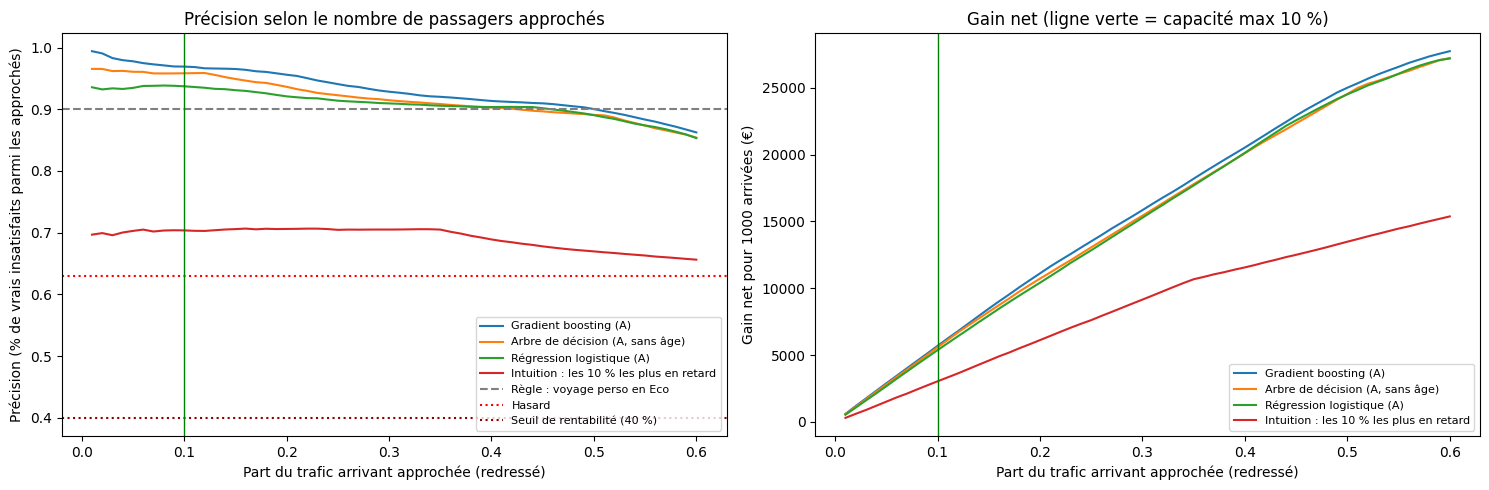

In [25]:
shares = np.linspace(0.01, 0.6, 60)
show = ["Gradient boosting (A)", "Arbre de décision (A, sans âge)", "Régression logistique (A)", "Intuition : les 10 % les plus en retard"]
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for name in show:
    precs = [top_share_precision(oof[name], y, W, s) for s in shares]
    axes[0].plot(shares, precs, label=name)
    axes[1].plot(shares, [net_gain_per_1000(p, s) for p, s in zip(precs, shares)], label=name)
rule_a = rules["Règle : voyage perso en Eco/Eco+ (jeu A)"].values
axes[0].axhline(np.average(y[rule_a], weights=W[rule_a]), ls="--", c="grey", label="Règle : voyage perso en Eco")
axes[0].axhline(np.average(y, weights=W), ls=":", c="red", label="Hasard")
axes[0].axhline(COST_APPROACH / GAIN_PER_TP, ls=":", c="darkred", label="Seuil de rentabilité (40 %)")
for ax in axes:
    ax.axvline(CAPACITY, c="green", lw=1); ax.set_xlabel("Part du trafic arrivant approchée (redressé)")
axes[0].set_ylabel("Précision (% de vrais insatisfaits parmi les approchés)"); axes[0].legend(fontsize=8)
axes[1].set_ylabel("Gain net pour 1000 arrivées (€)"); axes[1].legend(fontsize=8)
axes[0].set_title("Précision selon le nombre de passagers approchés")
axes[1].set_title("Gain net (ligne verte = capacité max 10 %)")
fig.tight_layout(); fig.savefig(FIG / "fig5_precision_gain.png", dpi=150); plt.show()

### 4.4 Lecture de la comparaison (trafic redressé)
- **Approcher au hasard est déjà rentable** (63 % > 40 %). La question n'est pas *faut-il approcher ?* mais *qui approcher dans la limite des 10 %*.
- **L'intuition « les plus en retard » est la pire des références** (≈ 70 %). Le retard joue, mais beaucoup moins que le profil du voyage.
- **La meilleure règle simple** (voyage perso en Eco/Eco Plus) atteint déjà 90 %. C'est la vraie barre à battre. Elle désigne 36 % du trafic réel (29 % des répondants) : bien plus que la capacité de 10 %.
- **Les approches de classification la battent** : arbre ≈ 95,9 %, gradient boosting ≈ 97,0 %, logistique ≈ 93,7 %. Les écarts entre plis (± 0,4 à 0,6 point) sont bien plus petits que les écarts entre approches.
- **Le redressement ne change pas les passagers choisis** : l'arbre entraîné sans poids donne exactement la même précision (95,9 %). Les règles du modèle se jouent à l'intérieur des classes, là où le poids est constant. Ce qui change, c'est le **contexte** : la référence « hasard » (63 % au lieu de 57 %) et le nombre d'insatisfaits laissés de côté.
- La **capacité des équipes (10 %)** est la vraie limite : le gain continue de monter au-delà, tant que la précision reste au-dessus de 40 %.

### 4.5 Comprendre ce que fait le modèle
**a) L'arbre de décision, lisible tel quel**

In [26]:
CHOSEN = "Arbre de décision (A, sans âge)"   # modèle retenu (voir 4.7)
tree_model = fit_w(make_tree(CAT_A, NUM_NO_AGE), train[CAT_A + NUM_NO_AGE], y, W)
feat = list(tree_model[0].get_feature_names_out())

FEATURE_LABELS_FR = {
    "Class": "Classe",
    "Customer Type": "Statut de fidélité",
    "Type of Travel": "Motif du voyage",
    "Age": "Âge",
    "Flight Distance": "Distance du vol",
    "Arrival Delay in Minutes": "Retard à l'arrivée (min)",
}
CATEGORY_LABELS_FR = {
    "Business": "Business", "Eco": "Eco", "Eco Plus": "Eco Plus",
    "Loyal Customer": "fidèle", "disloyal Customer": "non fidèle",
    "Business travel": "voyage professionnel", "Personal Travel": "voyage personnel",
}

def readable(name, op, thr):
    for c in CAT_A:
        if name.startswith(c + "_"):
            val = CATEGORY_LABELS_FR.get(name[len(c) + 1:], name[len(c) + 1:])
            return f"{FEATURE_LABELS_FR[c]} {'≠' if op == '<=' else '='} {val}"
    label = FEATURE_LABELS_FR.get(name, name)
    return f"{label} {'≤' if op == '<=' else '>'} {thr:.0f}"

def leaf_rules(model, X):
    t = model[-1].tree_
    leaves = model[-1].apply(model[0].transform(X))
    out = []
    def walk(node, conds):
        if t.children_left[node] == -1:
            m = leaves == node
            out.append({"règle (passagers concernés)": " ET ".join(conds),
                        "% des répondants": 100 * m.mean(), "% du trafic (redressé)": 100 * W[m].sum() / W.sum(),
                        "% neutres/insatisfaits": 100 * np.average(y[m], weights=W[m])})
            return
        f, thr = feat[t.feature[node]], t.threshold[node]
        walk(t.children_left[node], conds + [readable(f, "<=", thr)])
        walk(t.children_right[node], conds + [readable(f, ">", thr)])
    walk(0, [])
    return pd.DataFrame(out).sort_values("% neutres/insatisfaits", ascending=False).round(1).reset_index(drop=True)

rules_table = leaf_rules(tree_model, train[CAT_A + NUM_NO_AGE])
rules_table["% cumulé du trafic"] = rules_table["% du trafic (redressé)"].cumsum().round(1)
rules_table.to_csv(FIG / "regles_arbre.csv", index=False)
pd.set_option("display.max_colwidth", 140)
rules_table

,règle (passagers concernés),% des répondants,% du trafic (redressé),% neutres/insatisfaits,% cumulé du trafic
0,Classe ≠ Business ET Motif du voyage ≠ voyage professionnel ET Retard à l'arrivée (min) > 6 ET Classe = Eco Plus,1.2,1.7,97.2,1.7
1,Classe ≠ Business ET Motif du voyage ≠ voyage professionnel ET Retard à l'arrivée (min) > 6 ET Classe ≠ Eco Plus,8.6,10.5,95.7,12.2
2,Classe = Business ET Statut de fidélité ≠ non fidèle ET Motif du voyage = voyage personnel ET Retard à l'arrivée (min) > 6,0.8,0.5,93.2,12.7
3,Classe ≠ Business ET Motif du voyage = voyage professionnel ET Statut de fidélité ≠ fidèle ET Retard à l'arrivée (min) > 4,4.3,5.3,90.8,18.0
4,Classe ≠ Business ET Motif du voyage ≠ voyage professionnel ET Retard à l'arrivée (min) ≤ 6 ET Distance du vol ≤ 768,11.5,14.3,87.6,32.3
5,Classe ≠ Business ET Motif du voyage ≠ voyage professionnel ET Retard à l'arrivée (min) ≤ 6 ET Distance du vol > 768,7.7,9.5,86.2,41.8
6,Classe = Business ET Statut de fidélité ≠ non fidèle ET Motif du voyage = voyage personnel ET Retard à l'arrivée (min) ≤ 6,1.3,1.0,84.5,42.8
7,Classe ≠ Business ET Motif du voyage = voyage professionnel ET Statut de fidélité ≠ fidèle ET Retard à l'arrivée (min) ≤ 4,6.8,8.3,83.7,51.1
8,Classe = Business ET Statut de fidélité = non fidèle ET Distance du vol > 1602,0.6,0.4,77.6,51.5
9,Classe ≠ Business ET Motif du voyage = voyage professionnel ET Statut de fidélité = fidèle ET Retard à l'arrivée (min) > 6,4.6,5.8,65.3,57.3


**Comment lire l'arbre** : chaque ligne est un groupe de passagers défini par 2 à 4 critères simples, avec sa part du **trafic réel** (redressé). Le modèle approche d'abord les groupes du haut du tableau, jusqu'à atteindre 10 % du trafic. Concrètement, les 10 % signalés correspondent presque exactement à une règle : **voyage de loisirs, en Eco ou Eco Plus, arrivé avec plus de 6 minutes de retard** (≈ 12 % du trafic, 96-97 % de neutres ou insatisfaits). Le modèle ajoute donc une information à la meilleure règle simple : le retard à l'arrivée.

**Les plus insatisfaits** sont les voyageurs en Eco Plus en voyage personnel avec plus de 6 minutes de retard : **97,2 %** sont neutres ou insatisfaits (1,7 % du trafic). Le même profil en Eco atteint **95,7 %** (10,5 % du trafic).

Ce groupe pèse 9,8 % des **répondants** mais 12,2 % du **trafic** : le calcul brut sous-estimait sa taille réelle à l'arrivée.

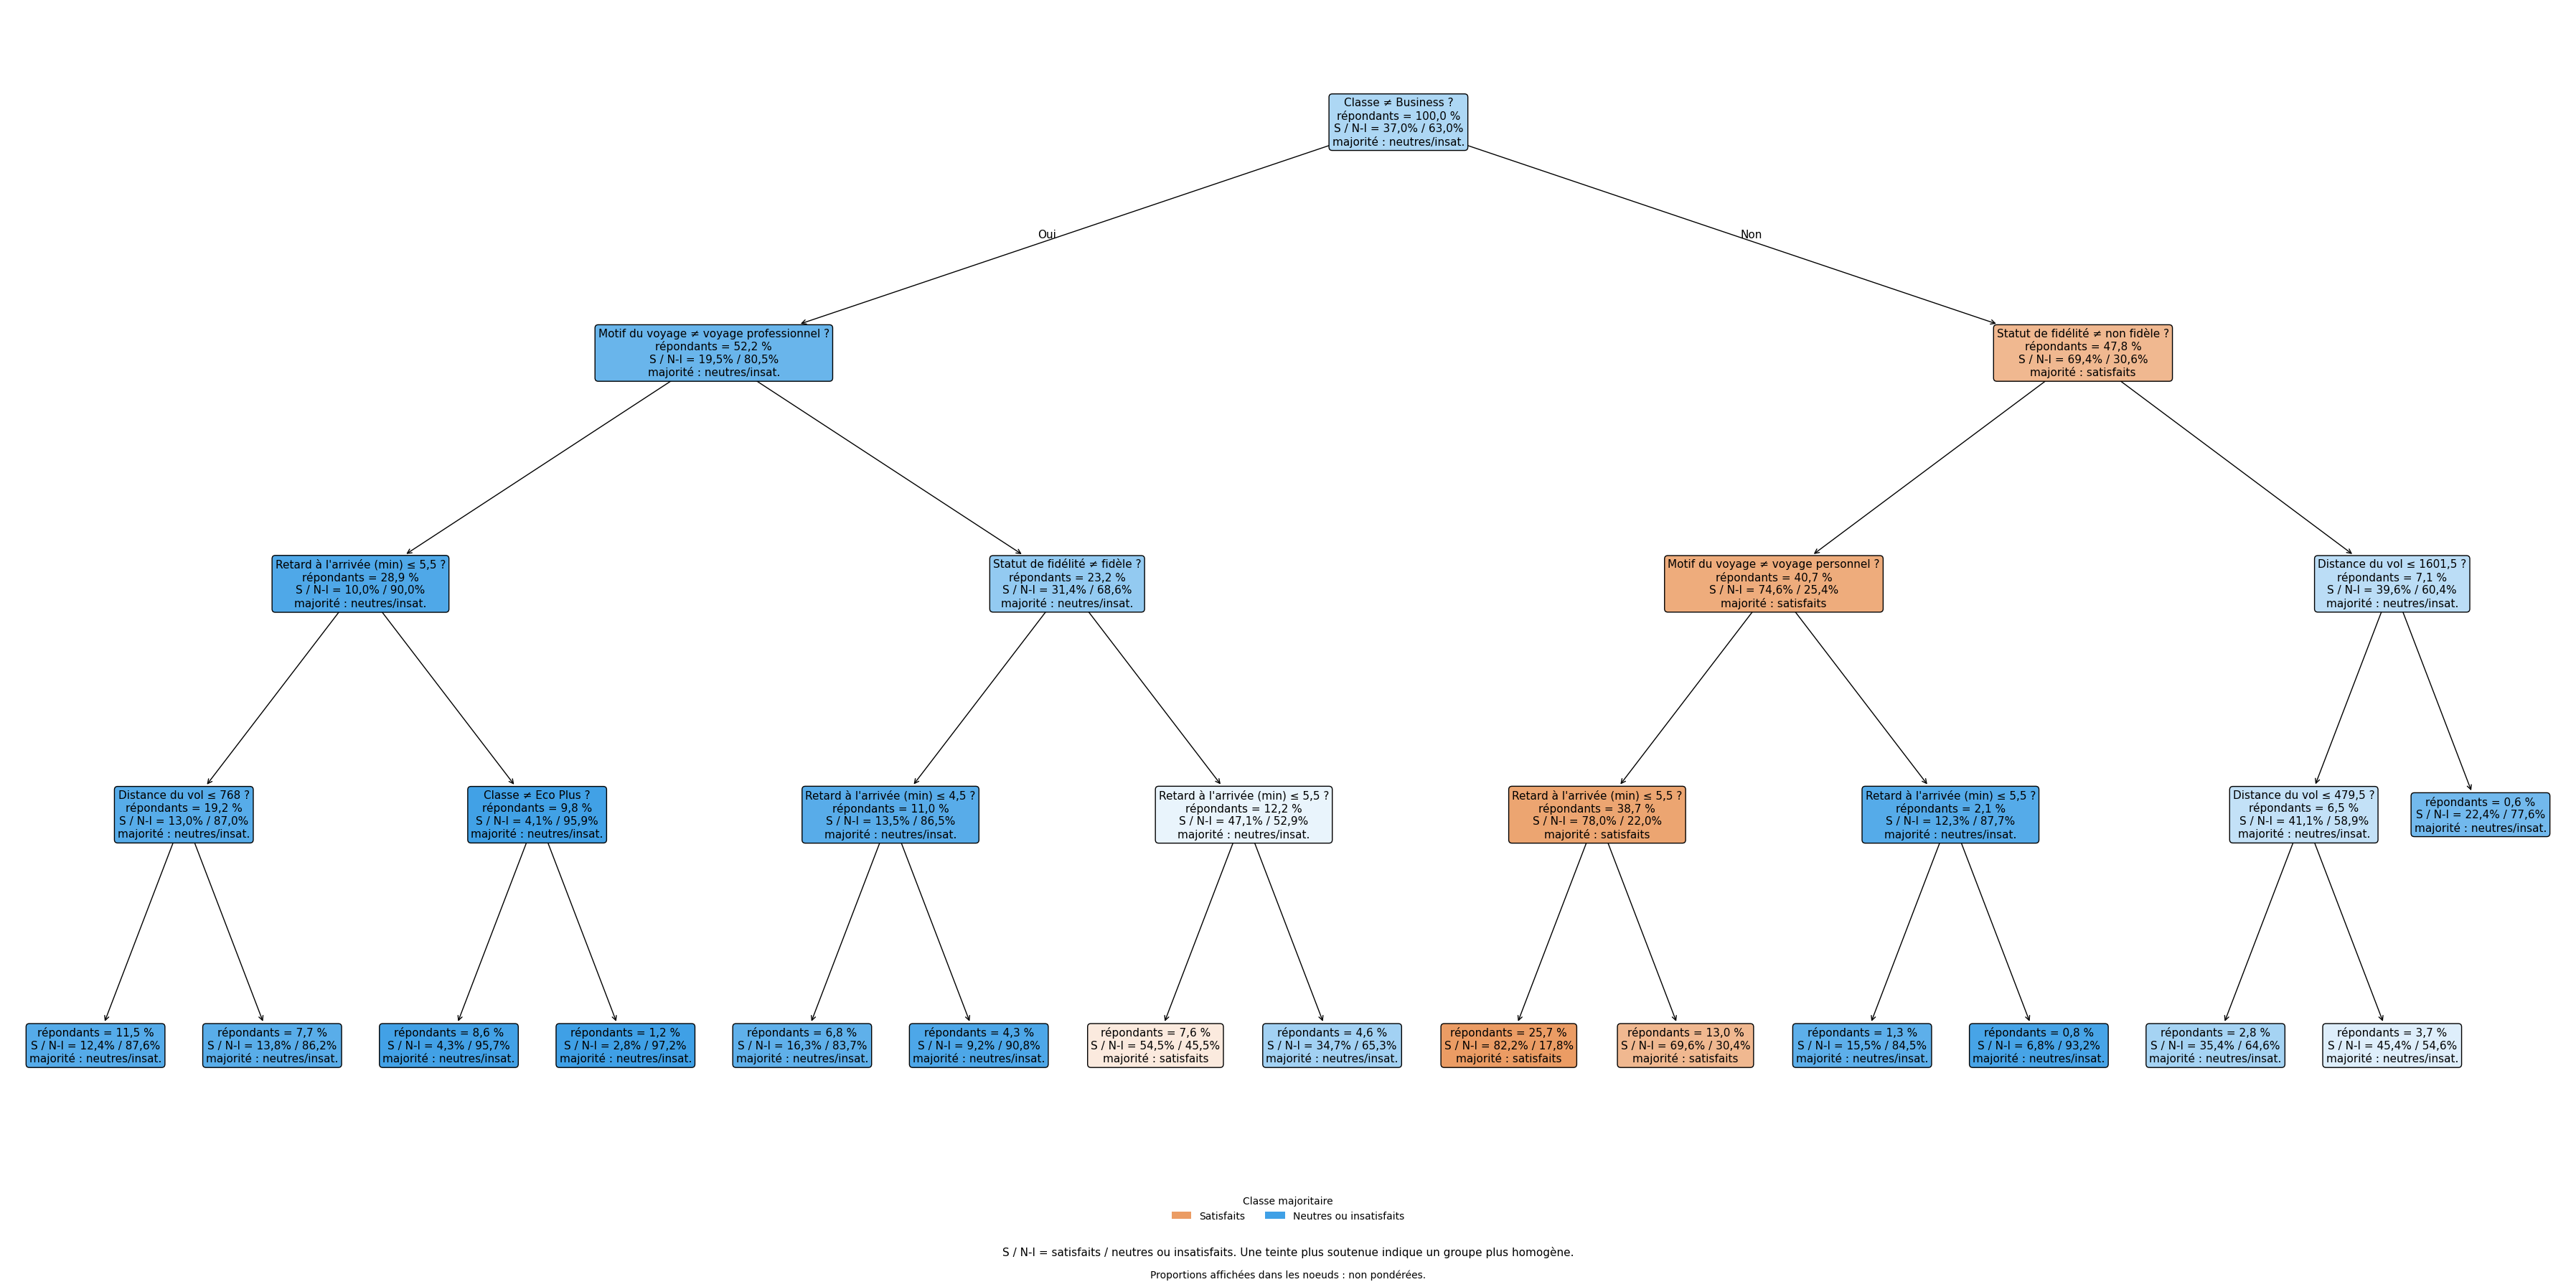

In [27]:
from matplotlib.patches import Patch

fig, ax = plt.subplots(figsize=(36, 18))
node_artists = [text for text in plot_tree(tree_model[-1], feature_names=feat,
                                              class_names=["satisfait", "neutre/insat."],
                                              filled=True, impurity=False, proportion=True,
                                              rounded=True, fontsize=11, ax=ax)
                if "class = " in text.get_text()]

for text in ax.texts:
    lines = text.get_text().splitlines()
    if len(lines) == 1 and lines[0].strip() in {"True", "False"}:
        text.set_text({"True": "Oui", "False": "Non"}[lines[0].strip()])
        continue
    if not lines:
        continue
    feature, separator, threshold = lines[0].rpartition(" <= ")
    if separator:
        categorical = next((c for c in CAT_A if feature.startswith(c + "_")), None)
        if categorical:
            value = CATEGORY_LABELS_FR.get(feature[len(categorical) + 1:], feature[len(categorical) + 1:])
            lines[0] = f"{FEATURE_LABELS_FR[categorical]} ≠ {value} ?"
        else:
            label = FEATURE_LABELS_FR.get(feature, feature)
            lines[0] = f"{label} ≤ {float(threshold):g} ?".replace(".", ",")
    for i, line in enumerate(lines):
        if line.startswith("samples = "):
            lines[i] = "répondants = " + line.split(" = ", 1)[1].replace(".", ",").replace("%", " %")
        elif line.startswith("value = ["):
            values = [float(value) for value in line.split("[", 1)[1].rstrip("]").split(",")]
            parts = [f"{value:.1%}".replace(".", ",") for value in values]
            lines[i] = f"S / N-I = {parts[0]} / {parts[1]}"
        elif line.startswith("class = "):
            label = line.split(" = ", 1)[1]
            lines[i] = "majorité : " + {"satisfait": "satisfaits", "neutre/insat.": "neutres/insat."}.get(label, label)
    text.set_text("\n".join(lines))

class_colors = {}
if len(node_artists) != tree_model[-1].tree_.node_count:
    raise RuntimeError("Impossible d'associer les couleurs aux noeuds de l'arbre.")
for node_id, node_artist in enumerate(node_artists):
    values = tree_model[-1].tree_.value[node_id][0]
    label = tree_model[-1].classes_[int(np.argmax(values))]
    color = node_artist.get_bbox_patch().get_facecolor()
    saturation = max(color[:3]) - min(color[:3])
    if label not in class_colors or saturation > class_colors[label][0]:
        class_colors[label] = (saturation, color)
legend_handles = [
    Patch(facecolor=class_colors[0][1], label="Satisfaits"),
    Patch(facecolor=class_colors[1][1], label="Neutres ou insatisfaits"),
]
fig.legend(handles=legend_handles, loc="lower center", bbox_to_anchor=(0.5, 0.045), ncol=2,
           frameon=False, title="Classe majoritaire")
fig.text(0.5, 0.025, "S / N-I = satisfaits / neutres ou insatisfaits. Une teinte plus soutenue indique un groupe plus homogène.",
         ha="center", fontsize=11)
fig.text(0.5, 0.008, "Proportions affichées dans les noeuds : non pondérées.", ha="center", fontsize=10)
fig.tight_layout(rect=(0, 0.09, 1, 1))
fig.savefig(FIG / "fig6_arbre.png", dpi=130, bbox_inches="tight"); plt.show()

**b) Sur quoi s'appuie le gradient boosting** (perte de performance quand on brouille une variable)

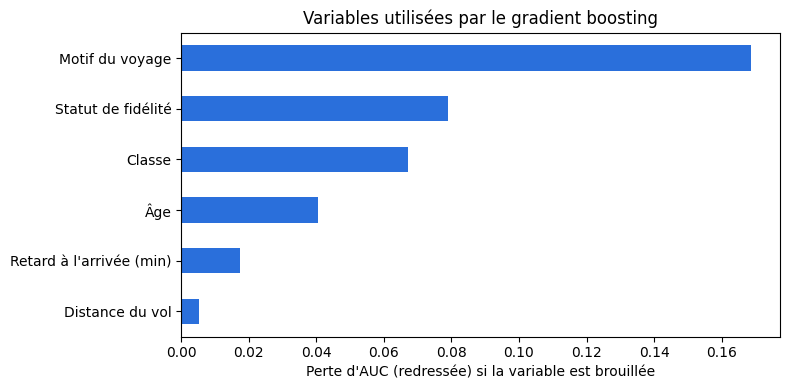

In [28]:
hgb_model = make_hgb(CAT_A, NUM)
tr, te = folds[0]
fit_w(hgb_model, train.iloc[tr][CAT_A + NUM], y[tr], W[tr])
imp = permutation_importance(hgb_model, train.iloc[te][CAT_A + NUM], y[te], scoring="roc_auc",
                             n_repeats=5, random_state=SEED, sample_weight=W[te])
importance = pd.Series(imp.importances_mean, index=CAT_A + NUM).sort_values()
ax = importance.plot.barh(figsize=(8, 4), color="#2a6fdb")
ax.set_yticks(range(len(importance)), [FEATURE_LABELS_FR.get(name, name) for name in importance.index])
ax.set_xlabel("Perte d'AUC (redressée) si la variable est brouillée"); ax.set_title("Variables utilisées par le gradient boosting")
plt.tight_layout(); plt.savefig(FIG / "fig7_importance.png", dpi=150); plt.show()

**c) Qui le modèle demande-t-il d'approcher ?** Profil des 10 % de passagers signalés (scores hors-pli, 10 % du trafic redressé)

In [29]:
def profile(t, w):
    avg = lambda s: np.average(s, weights=w)
    return pd.Series({
        "% voyage perso": avg(t["Type of Travel"] == "Personal Travel"),
        "% Eco": avg(t["Class"] == "Eco"),
        "% Eco Plus": avg(t["Class"] == "Eco Plus"),
        "% Business": avg(t["Class"] == "Business"),
        "% non fidèles": avg(t["Customer Type"] == "disloyal Customer"),
        "% avec retard > 15 min": avg(t["Arrival Delay in Minutes"] > 15),
        "% de mineurs": avg(t["Age"] < 18),
        "% réellement neutres/insat.": avg(t[TARGET]),
    })

flagged = {}
for n in ["Arbre de décision (A, sans âge)", "Arbre de décision (A, sans âge) - NON redressé", "Gradient boosting (A)"]:
    m = top_mask(oof[n], W)
    flagged[n] = profile(train[m], W[m])
flagged["tout le trafic (redressé)"] = profile(train, W)
pd.DataFrame(flagged).round(2)

,"Arbre de décision (A, sans âge)","Arbre de décision (A, sans âge) - NON redressé",Gradient boosting (A),tout le trafic (redressé)
% voyage perso,1.00,1.00,0.76,0.37
% Eco,0.84,0.84,0.77,0.55
% Eco Plus,0.16,0.16,0.17,0.10
% Business,0.00,0.00,0.06,0.35
% non fidèles,0.01,0.01,0.23,0.19
% avec retard > 15 min,0.66,0.66,0.60,0.23
% de mineurs,0.18,0.18,0.15,0.09
% réellement neutres/insat.,0.96,0.96,0.97,0.63


**d) Les groupes les plus interrogés ne sont pas forcément les plus signalés**
Pour chaque classe : sa part dans l'enquête, sa part dans le trafic, sa part parmi les passagers signalés, et la part de ses insatisfaits que le programme atteint (couverture).

,% de l'enquête,% du trafic,% des insatisfaits (trafic),% des signalés - arbre redressé,% des signalés - arbre non redressé,précision dans la classe (%),couverture des insatisfaits de la classe (%)
Eco,45.0,55.0,71.0,84.2,84.2,95.6,18.0
Business,47.8,35.0,17.0,0.0,0.0,NaN,0.0
Eco Plus,7.2,10.0,12.0,15.8,15.8,97.1,20.3


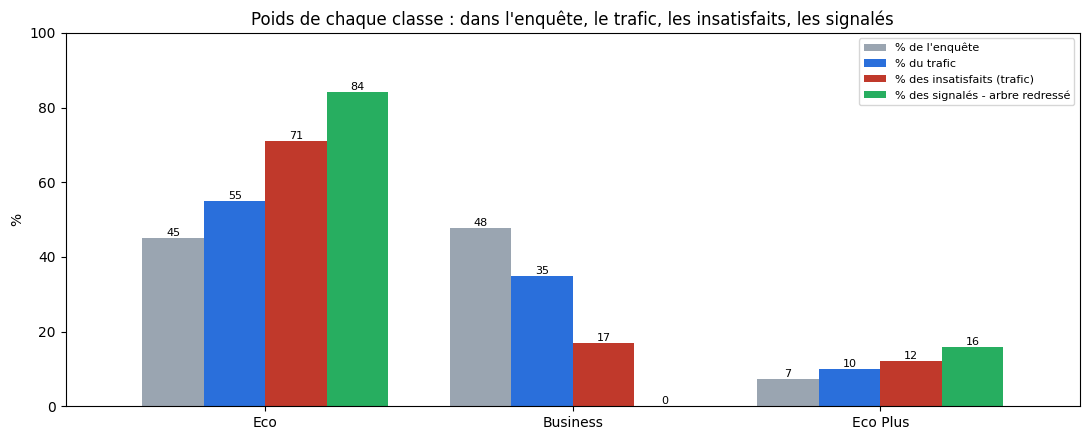

In [30]:
m_flag = top_mask(oof[CHOSEN], W)
m_flag_raw = top_mask(oof["Arbre de décision (A, sans âge) - NON redressé"], W)
by_class = {}
for k in CLASSES:
    mk = (train["Class"] == k).to_numpy()
    ins_k = mk & (y == 1)
    by_class[k] = {
        "% de l'enquête": 100 * mk.mean(),
        "% du trafic": 100 * W[mk].sum() / W.sum(),
        "% des insatisfaits (trafic)": 100 * W[ins_k].sum() / W[y == 1].sum(),
        "% des signalés - arbre redressé": 100 * W[m_flag & mk].sum() / W[m_flag].sum(),
        "% des signalés - arbre non redressé": 100 * W[m_flag_raw & mk].sum() / W[m_flag_raw].sum(),
        "précision dans la classe (%)": 100 * np.average(y[m_flag & mk], weights=W[m_flag & mk]) if (m_flag & mk).any() else np.nan,
        "couverture des insatisfaits de la classe (%)": 100 * W[m_flag & ins_k].sum() / W[ins_k].sum(),
    }
by_class = pd.DataFrame(by_class).T.round(1)
display(by_class)

cols = ["% de l'enquête", "% du trafic", "% des insatisfaits (trafic)", "% des signalés - arbre redressé"]
ax = by_class[cols].plot(kind="bar", figsize=(11, 4.5), color=["#9aa5b1", "#2a6fdb", "#c0392b", "#27ae60"], width=0.8, rot=0)
for c in ax.containers:
    ax.bar_label(c, fmt="%.0f", fontsize=8)
ax.set_ylabel("%"); ax.set_ylim(0, 100); ax.set_title("Poids de chaque classe : dans l'enquête, le trafic, les insatisfaits, les signalés")
ax.legend(fontsize=8); plt.tight_layout(); plt.savefig(FIG / "fig8_signales_par_classe.png", dpi=150); plt.show()

**Lecture**
- La **Business**, la classe la plus interrogée (48 % de l'enquête), ne représente que 17 % des insatisfaits et **0 % des signalés** : ses insatisfaits sont dispersés dans des groupes où le taux d'insatisfaction est trop bas pour justifier une approche à capacité limitée.
- L'**Eco**, sous-interrogée, représente 71 % des insatisfaits et 84 % des signalés, avec 96 % de précision.
- L'**Eco Plus**, la plus petite classe de l'enquête (7 %), représente 16 % des signalés, avec la **meilleure précision** (97 %) : un petit quota de sondage ne fait pas un groupe négligeable.
- **Couverture** : avec 100 approches pour 1 000 arrivées, on atteint ≈ 18-20 % des insatisfaits d'Eco et d'Eco Plus. La limite vient de la capacité, pas du modèle.
- **Point de vigilance** : aucun passager Business n'est approché. C'est un choix rentable, mais un choix commercial (clients à forte valeur) : le directeur peut décider de réserver une petite part de la capacité aux Business non fidèles (≈ 55-78 % d'insatisfaits selon la distance).

### 4.6 Ce que coûtent les erreurs
À capacité fixe (100 approches pour 1 000 arrivées), deux erreurs sont possibles :
- **faux positif** : approcher un passager déjà satisfait. On perd 40 € pour rien.
- **faux négatif** : ne pas approcher un insatisfait. On manque en moyenne 100 € récupérables. Mais avec 630 insatisfaits (trafic redressé) pour 100 places, la plupart des insatisfaits sont manqués **par manque de capacité**, quel que soit le modèle.

In [31]:
rows = {}
base_insat = 1000 * np.average(y, weights=W)
for name in ["Hasard", "Règle : voyage perso en Eco/Eco+ (jeu A)", "Arbre de décision (A, sans âge)", "Gradient boosting (A)"]:
    prec = comparison.loc[name, "précision top 10 %"]
    n = 1000 * CAPACITY; tp = n * prec; fp = n - tp
    rows[name] = {"approchés": n, "vrais insatisfaits approchés": tp, "satisfaits approchés (faux +)": fp,
                  "coût des faux + (€)": fp * COST_APPROACH,
                  "insatisfaits non approchés": base_insat - tp,
                  "revenu préservé (€)": tp * GAIN_PER_TP, "gain net (€)": net_gain_per_1000(prec)}
print(f"Pour 1000 passagers arrivants (trafic redressé : {base_insat:.0f} neutres/insatisfaits) :")
pd.DataFrame(rows).round(0)

Pour 1000 passagers arrivants (trafic redressé : 630 neutres/insatisfaits) :


,Hasard,Règle : voyage perso en Eco/Eco+ (jeu A),"Arbre de décision (A, sans âge)",Gradient boosting (A)
approchés,100.0,100.0,100.0,100.0
vrais insatisfaits approchés,63.0,90.0,96.0,97.0
satisfaits approchés (faux +),37.0,10.0,4.0,3.0
coût des faux + (€),1480.0,400.0,164.0,120.0
insatisfaits non approchés,567.0,540.0,534.0,533.0
revenu préservé (€),6300.0,9000.0,9590.0,9700.0
gain net (€),2300.0,5000.0,5590.0,5700.0


In [32]:
# Robustesse : le classement des approches change-t-il si les hypothèses du directeur sont fausses ?
scen = []
for churn in [1 / 4, 1 / 3, 1 / 2]:
    for recov in [0.25, 0.5, 0.75]:
        g = LOST_REVENUE * churn * recov
        row = {"churn": f"{churn:.0%}", "récupération": f"{recov:.0%}", "valeur d'une approche réussie (€)": g}
        for name in ["Règle : voyage perso en Eco/Eco+ (jeu A)", "Arbre de décision (A, sans âge)", "Gradient boosting (A)"]:
            row[name] = net_gain_per_1000(comparison.loc[name, "précision top 10 %"], gain=g)
        scen.append(row)
sensitivity = pd.DataFrame(scen).round(0)
sensitivity.to_csv(FIG / "sensibilite_hypotheses.csv", index=False)
sensitivity

,churn,récupération,valeur d'une approche réussie (€),Règle : voyage perso en Eco/Eco+ (jeu A),"Arbre de décision (A, sans âge)",Gradient boosting (A)
0,25%,25%,38.0,-625.0,-404.0,-362.0
1,25%,50%,75.0,2750.0,3192.0,3275.0
2,25%,75%,112.0,6125.0,6789.0,6912.0
3,33%,25%,50.0,500.0,795.0,850.0
4,33%,50%,100.0,5000.0,5590.0,5700.0
5,33%,75%,150.0,9500.0,10385.0,10550.0
6,50%,25%,75.0,2750.0,3192.0,3275.0
7,50%,50%,150.0,9500.0,10385.0,10550.0
8,50%,75%,225.0,16250.0,17578.0,17825.0


**Lecture**
- Dans les 9 scénarios, **le classement des approches ne change pas** (gradient boosting ≥ arbre > règle simple). Le choix du modèle ne dépend donc pas des hypothèses économiques.
- **Le gain, lui, en dépend fortement** : d'environ −0,4 k€ à +17,6 k€ pour 1 000 arrivées, selon le scénario.
- **Dans le scénario le plus pessimiste** (25 % de départs, 25 % de récupérés), une approche réussie ne vaut que 37,50 €, moins que les 40 € qu'elle coûte. **Le programme perd alors de l'argent, quel que soit le modèle.** Le meilleur modèle limite seulement la perte.
- Conclusion : le taux de récupération et la part réelle de départs sont **les chiffres à mesurer en priorité** pendant un pilote, avant de généraliser le programme.

### 4.8 Robustesse à l'hypothèse sur le mix de classes
Le mix réel du trafic n'est pas fourni : on refait les calculs clés sous plusieurs mix (toujours Eco > Business > Eco Plus), plus l'enquête brute pour comparaison. On ajoute une lecture **« classes à poids égal »** : chaque classe compte pour 1/3, quelle que soit sa taille dans l'enquête ou dans le trafic. Elle répond à une autre question : *qu'est-ce qui compte pour chaque type de voyageur, à égalité ?* Les scores hors-pli des modèles sont réutilisés ; seuls les poids d'évaluation changent. Les résultats sont résumés dans un graphique en trois parties.

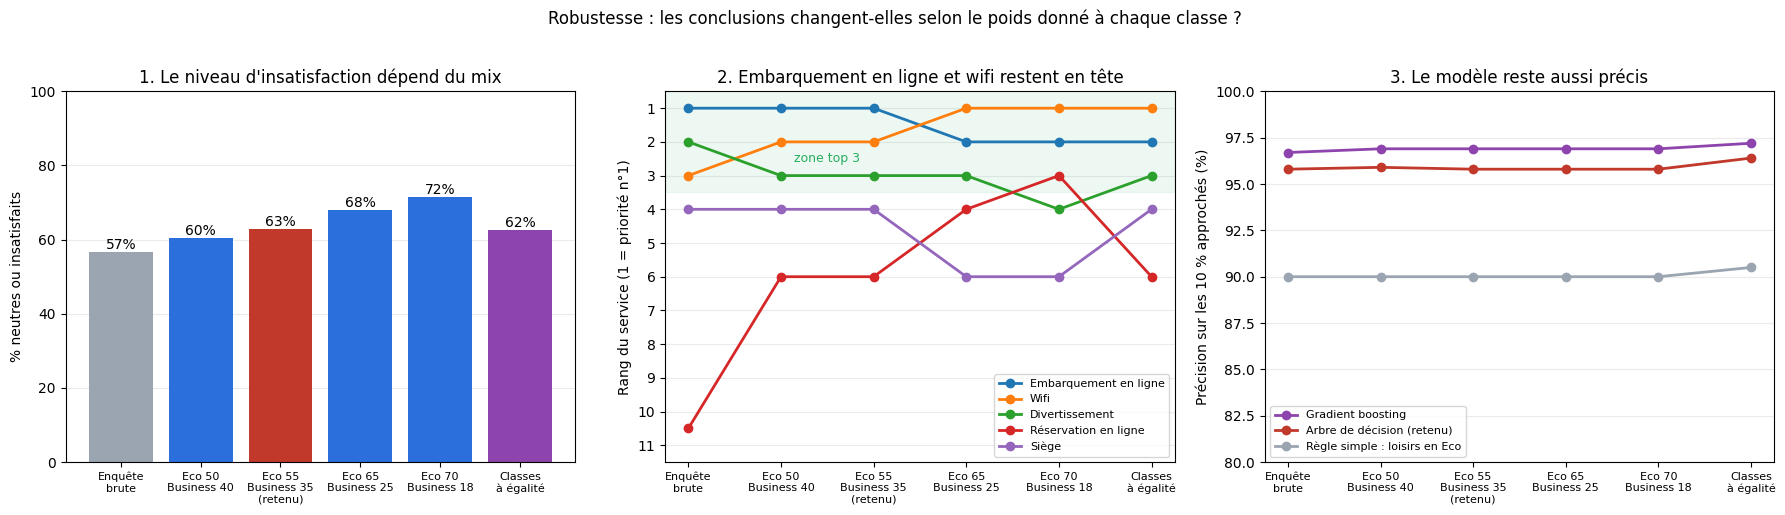

In [33]:
scen = []
for label, mx in {"Enquête brute (non redressée)": None, **MIX_SCENARIOS}.items():
    w_s = np.ones(len(train)) if mx is None else class_weights(train, mx)
    links = (drivers["lien brut (enquête)"] if mx is None else
             pd.Series({c: sum(mx[k] * drivers.loc[c, f"lien {k}"] for k in CLASSES) for c in SERVICES})).sort_values(ascending=False)
    flag_a = rules["Règle : voyage perso en Eco/Eco+ (jeu A)"].values
    row = {"mix de classes": label,
           "% neutres/insat.": 100 * np.average(y, weights=w_s),
           "top 3 services (lien)": ", ".join(links.index[:3]),
           "précision règle perso Eco": 100 * np.average(y[flag_a], weights=w_s[flag_a])}
    for name in ["Arbre de décision (A, sans âge)", "Gradient boosting (A)"]:
        prec = top_share_precision(oof[name], y, w_s)
        row[f"précision {name}"] = 100 * prec
        row[f"gain {name} (€/1000)"] = net_gain_per_1000(prec)
    scen.append(row)
mix_sensitivity = pd.DataFrame(scen).set_index("mix de classes").round(1)

# Rang de chaque service selon le mix (1 = lien le plus fort)
ranks = {}
for label, mx in {"Enquête brute (non redressée)": None, **MIX_SCENARIOS}.items():
    links = (drivers["lien brut (enquête)"] if mx is None else
             pd.Series({c: sum(mx[k] * drivers.loc[c, f"lien {k}"] for k in CLASSES) for c in SERVICES}))
    ranks[label] = links.rank(ascending=False)
ranks = pd.DataFrame(ranks)

short = ["Enquête\nbrute", "Eco 50\nBusiness 40", "Eco 55\nBusiness 35\n(retenu)", "Eco 65\nBusiness 25", "Eco 70\nBusiness 18", "Classes\nà égalité"]
x = np.arange(len(short))
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

colors = ["#9aa5b1"] + ["#2a6fdb"] * 4 + ["#8e44ad"]
colors[2] = "#c0392b"
bars = axes[0].bar(x, mix_sensitivity["% neutres/insat."], color=colors)
axes[0].bar_label(bars, fmt="%.0f%%")
axes[0].set_ylim(0, 100); axes[0].set_ylabel("% neutres ou insatisfaits")
axes[0].set_title("1. Le niveau d'insatisfaction dépend du mix")

svc_fr = {"Online boarding": "Embarquement en ligne", "Inflight wifi service": "Wifi",
          "Inflight entertainment": "Divertissement", "Ease of Online booking": "Réservation en ligne",
          "Seat comfort": "Siège"}
for svc, lab in svc_fr.items():
    axes[1].plot(x, ranks.loc[svc], marker="o", lw=2, label=lab)
axes[1].set_ylim(11.5, 0.5); axes[1].set_yticks(range(1, 12))
axes[1].axhspan(0.5, 3.5, color="#27ae60", alpha=0.08)
axes[1].text(1.5, 2.5, "zone top 3", color="#27ae60", ha="center", va="center", fontsize=9)
axes[1].set_ylabel("Rang du service (1 = priorité n°1)"); axes[1].legend(fontsize=8, loc="lower right")
axes[1].set_title("2. Embarquement en ligne et wifi restent en tête")

for name, lab, col in [("précision Gradient boosting (A)", "Gradient boosting", "#8e44ad"),
                       ("précision Arbre de décision (A, sans âge)", "Arbre de décision (retenu)", "#c0392b"),
                       ("précision règle perso Eco", "Règle simple : loisirs en Eco", "#9aa5b1")]:
    axes[2].plot(x, mix_sensitivity[name], marker="o", lw=2, color=col, label=lab)
axes[2].set_ylim(80, 100); axes[2].set_ylabel("Précision sur les 10 % approchés (%)")
axes[2].legend(fontsize=8, loc="lower left")
axes[2].set_title("3. Le modèle reste aussi précis")

for ax in axes:
    ax.set_xticks(x, short, fontsize=8); ax.grid(axis="y", alpha=0.25); ax.set_axisbelow(True)
fig.suptitle("Robustesse : les conclusions changent-elles selon le poids donné à chaque classe ?", y=1.02)
fig.tight_layout(); fig.savefig(FIG / "fig9_sensibilite_mix.png", dpi=150, bbox_inches="tight"); plt.show()

**Lecture**
- **Le niveau d'insatisfaction dépend fortement du mix** : de 60,5 % à 71,5 % selon la part de l'Eco. Plus l'Eco pèse, plus le problème est gros. Ce chiffre doit être recalculé avec le vrai mix de la compagnie.
- **Les priorités d'investissement bougent dans le même sens** : embarquement en ligne et wifi restent toujours dans le top 3 ; dès que l'Eco dépasse ≈ 65 % du trafic, le **wifi passe n°1** et la **réservation en ligne entre dans le top 3**, à la place du divertissement (levier Business). Avec l'enquête brute, le divertissement apparaît n°2 : c'est l'erreur que provoque la sur-représentation de la Business.
- **Classes à poids égal** (1/3 chacune, la taille des groupes ne compte plus du tout) : 62,5 % de neutres/insatisfaits ; top 3 = wifi, embarquement en ligne, divertissement ; arbre ≈ 96,4 % de précision. **Les conclusions sont les mêmes** : la taille d'un groupe, dans l'enquête comme dans le trafic, ne fait pas ses priorités.
- **La précision et le gain du modèle ne bougent pas** (≈ 95,8 à 96,4 % et ≈ 5,6 k€ / 1 000 arrivées dans tous les mix) : les passagers ciblés sont tous en Eco / Eco Plus, et le modèle reste valable quel que soit le mix réel.

### 4.7 Choix du modèle à déployer : au-delà du meilleur score
| Critère | Règle simple | Arbre de décision | Gradient boosting |
|---|---|---|---|
| Précision top 10 % (trafic redressé) | ≈ 90 % | ≈ 96 % | ≈ 97 % |
| Le directeur peut l'expliquer à son comité exécutif | Oui | **Oui, règle par règle** | Non (importance des variables seulement) |
| L'agent peut comprendre pourquoi un passager est signalé | Oui | **Oui** | Non |
| Audit RGPD / non-discrimination | Facile | **Facile** | Plus difficile |
| Stable si le mix de classes réel diffère de l'hypothèse | Oui | **Oui** (4.8) | Oui |
| Maintenance | Aucune | Faible | Réentraînement régulier |

**Recommandation : déployer l'arbre de décision (jeu A), sans l'âge, entraîné sur l'enquête redressée**. Il bat la meilleure règle simple d'environ 590 € pour 1 000 arrivées, et ne perd qu'environ 110 € face au modèle le plus précis. En échange, **chaque signalement s'explique en une phrase**. C'est ce que demande un directeur qui « finance ce qu'il comprend ». Le gradient boosting reste une évolution possible, une fois la confiance installée par un pilote.

**Si le type de voyage n'est pas connu à l'atterrissage** : utiliser l'arbre du jeu B (≈ 93 %), en acceptant une précision plus faible.

**Minimisation** : l'arbre sans l'âge est aussi précis que l'arbre avec (≈ 95,9 % dans les deux cas). L'âge n'apporte donc rien au ciblage et **il est retiré**. À l'inverse, le gradient boosting perd environ 1 point sans l'âge.

## 5. Protection des données : conditions d'usage

Le questionnaire a été collecté pour **mesurer** la satisfaction. Signaler des passagers aux agents d'aéroport est une **nouvelle finalité**, et elle concerne surtout des passagers qui n'ont jamais répondu (RGPD, art. 5-1-b et 6-4 : compatibilité de la finalité).

**Conditions pour que ce soit acceptable**
- **Base légale** : intérêt légitime, documenté par une **analyse d'impact (AIPD)**, et une information claire des passagers (conditions de transport, appli). Le passager peut **s'opposer** au signalement.
- **Effet uniquement positif** : un signalement ne peut déclencher qu'une attention (geste, information, aide), jamais un traitement défavorable.
- **Minimisation et durée** : seules les variables du tableau ci-dessous. Le score est calculé à l'arrivée et supprimé après le vol, sans profil « passager à risque » conservé.
- **Contrôle** : vérifier régulièrement que le taux de signalement ne pénalise aucun groupe (âge, fidélité, classe), et mesurer la précision réelle pendant un pilote. Recalculer les poids de redressement avec le **mix de classes réellement observé** à l'arrivée.

**Chaque variable du modèle**
| Variable | Acceptable ? | Condition |
|---|---|---|
| Classe, distance, retard | Oui | Données opérationnelles, peu sensibles |
| Fidélité | Oui | Déjà traitée dans le programme de fidélité |
| Type de voyage | Oui, s'il est **déclaré** (tarif ou compte entreprise) | Ne jamais le deviner à partir d'autres données |
| Âge | **Non retenu** : l'arbre sans âge est aussi précis | Minimisation : donnée inutile au ciblage |
| Genre | **Non** | Aucun intérêt prédictif, risque de discrimination |
| Notes du questionnaire | **Non** | Pas disponibles à l'atterrissage, et finalité différente |

**Enfants** : en voyage personnel, l'âge ne change rien à l'insatisfaction (voir 2.3). Il n'y a donc **aucune raison de cibler les enfants en tant que tels**. Un mineur n'est **jamais approché seul** : le signalement est rattaché à la réservation, et l'approche se fait auprès de l'adulte responsable.

**Ce que voit l'agent** : nom, numéro de vol et un motif lisible, tiré de la règle de l'arbre (par exemple « vol de loisirs en Eco, arrivé en retard »). **Pas** de score, pas d'âge, pas de mention « client à risque ».

## 6. Évaluation finale sur `test.csv` : UNE SEULE FOIS

⚠️ Cette cellule est la **seule** qui lit `test.csv` (vérifiable : aucune autre cellule ne l'ouvre). Le modèle, les variables et la capacité ont été figés **avant** cette lecture (sections 4.5 et 4.7), uniquement à partir de la validation croisée sur `train`.

- `RUN_FINAL_TEST = True` : le verrou est ouvert pour le rendu final.
- Le modèle évalué est réentraîné sur **tout** `train` (avec les poids de redressement), puis appliqué tel quel à `test`.
- Les chiffres obtenus sont ceux du rapport (page 1 et section 4). Ils sont **comparés** à la validation croisée, mais ne servent **jamais** à revenir modifier le modèle.
- Le résultat est aussi enregistré dans `figures/evaluation_finale_test.csv`.

In [34]:
# Modèle figé en 4.5 / 4.7 à partir de la validation croisée sur train uniquement
assert CHOSEN == "Arbre de décision (A, sans âge)", "Le modèle évalué doit être celui choisi AVANT de lire test.csv"
RUN_FINAL_TEST = True              # verrou ouvert pour le rendu final : test.csv n'est lu qu'ici

if RUN_FINAL_TEST:
    factory, cat, num = CANDIDATES[CHOSEN]
    final_model = fit_w(factory(cat, num), train[cat + num], y, W)   # réentraîné sur tout train
    test, test_audit = load(DATA_DIR / "test.csv")   # première et unique lecture du fichier test
    y_test, w_test = test[TARGET].values, test["w"].values   # test redressé au même mix de trafic réel
    s_test = final_model.predict_proba(test[cat + num])[:, 1]
    s_test = s_test + np.random.RandomState(SEED).rand(len(s_test)) * 1e-6   # départage des ex aequo, comme en 4.3
    auc_t = roc_auc_score(y_test, s_test, sample_weight=w_test)
    prec_t = top_share_precision(s_test, y_test, w_test)

    print(f"Modèle : {CHOSEN}")
    print(f"Passagers test : {len(test):,} | retards manquants exclus : {test_audit['missing_arrival']} | "
          f"taux de neutres/insatisfaits : brut {y_test.mean():.1%}, redressé {np.average(y_test, weights=w_test):.1%}")
    final = pd.DataFrame({
        "validation croisée (train)": [comparison.loc[CHOSEN, "AUC"], comparison.loc[CHOSEN, "précision top 10 %"],
                                       comparison.loc[CHOSEN, "gain net / 1000 arrivées (€)"]],
        "test (une seule fois)": [auc_t, prec_t, net_gain_per_1000(prec_t)],
    }, index=["AUC (redressée)", "précision top 10 %", "gain net / 1000 arrivées (€)"])
    final["écart test - CV"] = final["test (une seule fois)"] - final["validation croisée (train)"]
    final.round(3).to_csv(FIG / "evaluation_finale_test.csv")
    display(final.round(3))
else:
    print("Évaluation finale non lancée (RUN_FINAL_TEST = False).")

Modèle : Arbre de décision (A, sans âge)
Passagers test : 25,893 | retards manquants exclus : 83 | taux de neutres/insatisfaits : brut 56.1%, redressé 62.5%


,validation croisée (train),test (une seule fois),écart test - CV
AUC (redressée),0.848,0.845,-0.003
précision top 10 %,0.959,0.961,0.002
gain net / 1000 arrivées (€),5587.480,5609.767,22.287


## 7. Recommandations

### 7.1 Problématique 1 : savoir ce qui fait la satisfaction, pour investir le budget
| # | 1. Facteur observé | 2. Justification analytique | 3. Caractère actionnable | 4. Impact attendu |
|---|---|---|---|---|
| R1 | **Embarquement en ligne** | Lien le plus fort une fois redressé (0,48), dans les 3 classes ; ×2,4 chances d'être satisfait par point à profil égal ; de 3 à 5 : insatisfaction de 89 % à 17 % | Oui : parcours digital (appli, carte d'embarquement mobile). Coût modéré | Levier transversal (100 % du trafic). Viser la note 5 : c'est l'excellence qui crée la satisfaction. À valider par un test A/B |
| R2 | **Wifi à bord**, ciblé Eco / Eco Plus | 1er levier en Eco (0,58) et Eco Plus (0,64), soit 65 % du trafic et 83 % des insatisfaits ; ×2,7 à profil égal ; note la plus basse (2,8). L'enquête brute le classait 3e | Oui : équipement des appareils moyen-courrier en priorité | Le plus fort potentiel en volume ; effet anormalement net (données possiblement synthétiques) : à confirmer sur un pilote de quelques lignes |
| R3 | **Réservation en ligne** | Remonte du 10e au 5e rang une fois redressée ; +1,9 point de note entre satisfaits et insatisfaits en loisirs Eco (31 % du trafic) | Oui : site et appli | Cible le premier réservoir d'insatisfaits (loisirs Eco, 90 %) |
| R4 | **Confort cabine**, ciblé Business | Lien fort seulement en Business (0,38 à 0,49), quasi nul en Eco ; son poids brut était gonflé par la sur-représentation de la Business | Oui, mais coûteux (sièges, divertissement) | Protège la classe la plus rentable (35 % du trafic) ; ne pas l'étendre à l'Eco |
| R5 | **Ponctualité : seuil de 15 min** | +6 pts d'insatisfaction de 0 à 15 min, +12 pts au-delà, dans tous les segments ; probablement causal (le retard précède le questionnaire) | Partiellement (opérations, rotations) | Viser le seuil des 15 min plutôt que les longs retards ; sert aussi au ciblage (R7) |
| R6 | **Services de base** (propreté, enregistrement, restauration) | Pénalité > bonus : ils déçoivent quand ils sont mauvais, mais n'enthousiasment pas | Oui | Maintenir le niveau, **ne pas surinvestir** |
| — | Porte, horaires, genre | Aucun lien | — | **Pas de budget** |

### 7.2 Problématique 2 : repérer les passagers probablement mécontents avant leur sortie de l'aéroport
| # | 1. Facteur observé | 2. Justification analytique | 3. Caractère actionnable | 4. Impact attendu |
|---|---|---|---|---|
| R7 | **Loisirs + Eco / Eco Plus + retard > 6 min** | Règle principale de l'arbre : ≈ 12 % du trafic, 96-97 % de neutres ou insatisfaits | Oui : 3 informations connues à l'atterrissage (réservation + opérations) ; respecte la capacité de 10 % | 96 approches utiles sur 100, contre 63 au hasard et 70 avec l'intuition « les plus en retard » |
| R8 | **Déployer l'arbre de décision (sans âge)** | Bat la meilleure règle simple de 6 pts de précision (≈ +590 € / 1 000 arrivées) ; seulement −1 pt face au gradient boosting | Oui : règles lisibles par le directeur et les agents ; audit RGPD facile | ≈ 5,6 k€ de gain net / 1 000 arrivées (hypothèses du directeur) ; stable quel que soit le mix de classes réel |
| R9 | **Capacité des équipes** | La précision reste > 40 % (rentabilité) bien au-delà de 10 % du trafic | Oui : renfort d'agents sur les vols de loisirs en retard | Augmenter la capacité rapporte plus que raffiner le modèle |
| R10 | **Pilote avant généralisation** | Le gain dépend surtout du taux de récupération et du taux de départ réels (−0,4 k€ à +17,6 k€) ; biais des répondants | Oui : quelques vols, groupe témoin | Mesure la vraie précision et la vraie rentabilité avant d'engager le budget |

### 7.3 Conclusion : trois profils types de passagers probablement mécontents
L'arbre de décision (4.5) fait ressortir trois profils lisibles à l'atterrissage. On les compare avec **les critères d'identification** fixés par le sujet et par le directeur :

| # | Critère | Seuil retenu | D'où vient-il ? |
|---|---|---|---|
| C1 | Connu au moment de l'atterrissage | Uniquement réservation, fidélité, opérations | « use only what the airline knows at that moment » |
| C2 | Très probablement mécontent | ≥ 90 % de neutres/insatisfaits | Au moins aussi bon que la meilleure règle simple (90 %) |
| C3 | Rentable à approcher | > 40 % de neutres/insatisfaits | 40 € par approche, 100 € par passager récupéré |
| C4 | Tient dans la capacité des équipes | ≤ 12 % du trafic | 1 arrivant sur 10 au maximum : au-delà, il faut tirer au hasard dans le groupe |
| C5 | Résultat stable, quel que soit le poids des classes | ≥ 90 % en trafic réel **et** avec chaque classe à 1/3 | Pour qu'aucune classe ne domine le résultat parce qu'elle est plus nombreuse |
| C6 | Motif d'approche concret à l'arrivée | Un **événement du voyage**, pas seulement un profil | L'agent sait quoi dire et quoi proposer |
| C7 | Aucune donnée sensible | Sans âge ni genre | Minimisation RGPD (section 5) |

,description,% du trafic,% neutres/insat. (trafic réel),% neutres/insat. (classes à 1/3),% des insatisfaits du trafic,% avec retard > 15 min,% de mineurs,gain net / 1000 arrivées (€),critères remplis
"P1 · Le vacancier en Eco, arrivé en retard","Voyage de loisirs, en Eco ou Eco Plus, arrivé avec plus de 6 min de retard",11.6,95.9,96.4,17.7,69.7,18.1,5590.0,7 / 7
P2 · Le voyageur pro occasionnel en Eco,"Voyage professionnel, en Eco ou Eco Plus, client non fidèle",13.6,86.5,87.8,18.7,25.1,8.2,4645.2,3 / 7
P3 · Le client Business non fidèle,"Voyage en Business, client non fidèle",5.2,60.4,60.4,5.0,20.7,2.1,1060.7,4 / 7


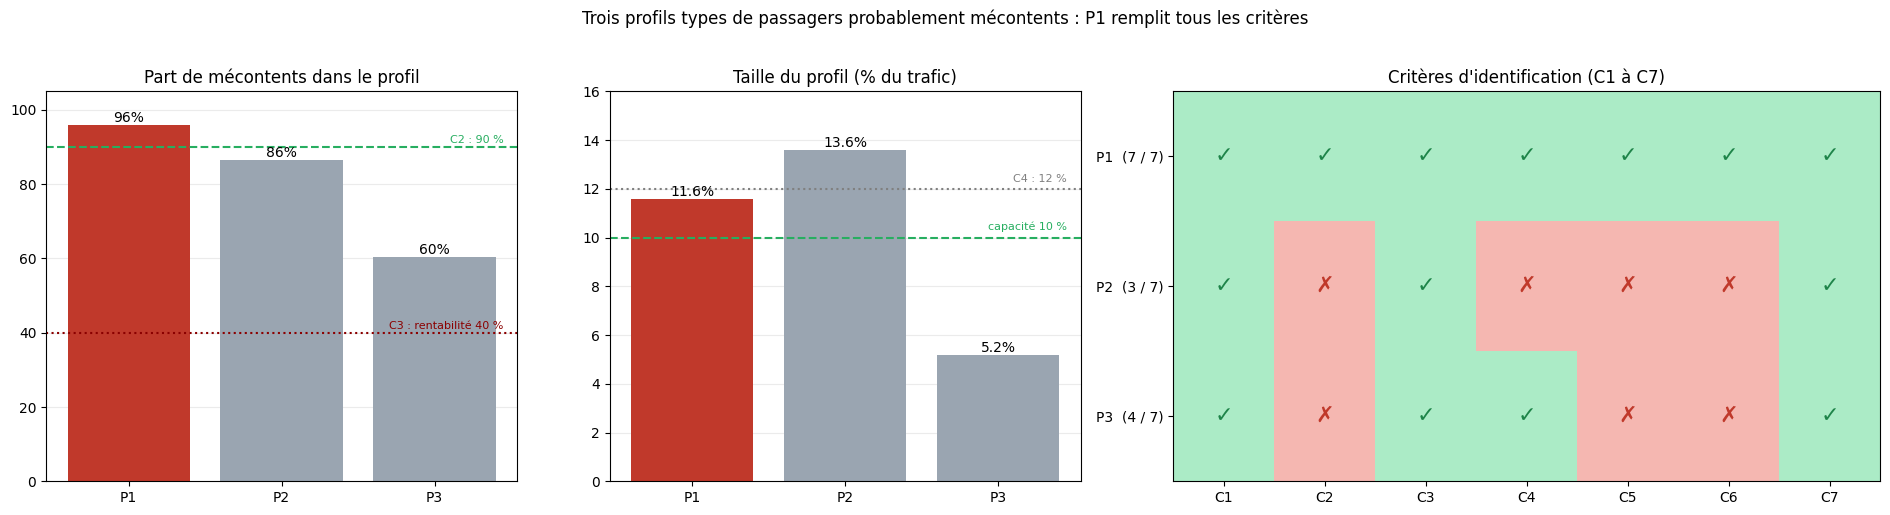

,C1 connu à l'atterrissage,C2 ≥ 90 % mécontents,C3 rentable (> 40 %),C4 ≤ 12 % du trafic,C5 stable (trafic et 1/3),C6 motif = événement du voyage,C7 sans âge ni genre
"P1 · Le vacancier en Eco, arrivé en retard",✓,✓,✓,✓,✓,✓,✓
P2 · Le voyageur pro occasionnel en Eco,✓,✗,✓,✗,✗,✗,✓
P3 · Le client Business non fidèle,✓,✗,✓,✓,✗,✗,✓


In [35]:
PROFILS = {
    "P1 · Le vacancier en Eco, arrivé en retard":
        (train["Type of Travel"] == "Personal Travel") & (train["Class"] != "Business") & (train["Arrival Delay in Minutes"] > 6),
    "P2 · Le voyageur pro occasionnel en Eco":
        (train["Type of Travel"] == "Business travel") & (train["Class"] != "Business") & (train["Customer Type"] == "disloyal Customer"),
    "P3 · Le client Business non fidèle":
        (train["Class"] == "Business") & (train["Customer Type"] == "disloyal Customer"),
}
DESCRIPTION = {
    "P1 · Le vacancier en Eco, arrivé en retard": "Voyage de loisirs, en Eco ou Eco Plus, arrivé avec plus de 6 min de retard",
    "P2 · Le voyageur pro occasionnel en Eco": "Voyage professionnel, en Eco ou Eco Plus, client non fidèle",
    "P3 · Le client Business non fidèle": "Voyage en Business, client non fidèle",
}
E = class_weights(train, MIX_EGAL)  # chaque classe compte pour 1/3
rows, checks = {}, {}
for name, m in PROFILS.items():
    m = m.to_numpy()
    insat, insat_egal = np.average(y[m], weights=W[m]), np.average(y[m], weights=E[m])
    share = W[m].sum() / W.sum()
    rows[name] = {
        "description": DESCRIPTION[name],
        "% du trafic": 100 * share,
        "% neutres/insat. (trafic réel)": 100 * insat,
        "% neutres/insat. (classes à 1/3)": 100 * insat_egal,
        "% des insatisfaits du trafic": 100 * W[m & (y == 1)].sum() / W[y == 1].sum(),
        "% avec retard > 15 min": 100 * np.average(train["Arrival Delay in Minutes"].to_numpy()[m] > 15, weights=W[m]),
        "% de mineurs": 100 * np.average(train["Age"].to_numpy()[m] < 18, weights=W[m]),
        "gain net / 1000 arrivées (€)": net_gain_per_1000(insat, share=min(share, CAPACITY)),
    }
    checks[name] = {
        "C1 connu à l'atterrissage": True,
        "C2 ≥ 90 % mécontents": insat >= 0.90,
        "C3 rentable (> 40 %)": insat > COST_APPROACH / GAIN_PER_TP,
        "C4 ≤ 12 % du trafic": share <= 0.12,
        "C5 stable (trafic et 1/3)": min(insat, insat_egal) >= 0.90,
        "C6 motif = événement du voyage": "retard" in name,
        "C7 sans âge ni genre": True,
    }
profils = pd.DataFrame(rows).T
num_cols = [c for c in profils.columns if c != "description"]
profils[num_cols] = profils[num_cols].astype(float).round(1)
checks = pd.DataFrame(checks).T
profils["critères remplis"] = checks.sum(axis=1).astype(str) + " / " + str(checks.shape[1])
display(profils)

fig, axes = plt.subplots(1, 3, figsize=(19, 5), gridspec_kw={"width_ratios": [1, 1, 1.5]})
labels = [n.split(" · ")[0] for n in profils.index]
best = checks.all(axis=1).to_numpy()
cols = np.where(best, "#c0392b", "#9aa5b1")

b = axes[0].bar(labels, profils["% neutres/insat. (trafic réel)"].astype(float), color=cols)
axes[0].bar_label(b, fmt="%.0f%%")
axes[0].axhline(90, ls="--", c="#27ae60"); axes[0].text(2.45, 91, "C2 : 90 %", color="#27ae60", ha="right", fontsize=8)
axes[0].axhline(40, ls=":", c="darkred"); axes[0].text(2.45, 41, "C3 : rentabilité 40 %", color="darkred", ha="right", fontsize=8)
axes[0].set_ylim(0, 105); axes[0].set_title("Part de mécontents dans le profil")

b = axes[1].bar(labels, profils["% du trafic"].astype(float), color=cols)
axes[1].bar_label(b, fmt="%.1f%%")
axes[1].axhline(100 * CAPACITY, ls="--", c="#27ae60"); axes[1].text(2.45, 10.3, "capacité 10 %", color="#27ae60", ha="right", fontsize=8)
axes[1].axhline(12, ls=":", c="grey"); axes[1].text(2.45, 12.3, "C4 : 12 %", color="grey", ha="right", fontsize=8)
axes[1].set_ylim(0, 16); axes[1].set_title("Taille du profil (% du trafic)")

grid = checks.to_numpy().astype(int)
axes[2].imshow(grid, cmap=plt.matplotlib.colors.ListedColormap(["#f5b7b1", "#abebc6"]), aspect="auto")
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        axes[2].text(j, i, "✓" if grid[i, j] else "✗", ha="center", va="center", fontsize=16,
                     color="#1e8449" if grid[i, j] else "#c0392b")
axes[2].set_xticks(range(grid.shape[1]), [c.split(" ", 1)[0] for c in checks.columns])
axes[2].set_yticks(range(len(labels)), [f"{l}  ({s})" for l, s in zip(labels, profils["critères remplis"])])
axes[2].set_title("Critères d'identification (C1 à C7)")
for ax in axes[:2]:
    ax.grid(axis="y", alpha=0.25); ax.set_axisbelow(True)
fig.suptitle("Trois profils types de passagers probablement mécontents : P1 remplit tous les critères", y=1.02)
fig.tight_layout(); fig.savefig(FIG / "fig10_profils_types.png", dpi=150, bbox_inches="tight"); plt.show()
checks.replace({True: "✓", False: "✗"})

**Les trois profils types**

**P1 · Le vacancier en Eco, arrivé en retard**, le profil qui remplit **tous les critères (7 / 7)**
- *Qui* : voyage de loisirs, en Eco ou Eco Plus, arrivé avec plus de 6 minutes de retard.
- *Pourquoi il est mécontent* : il cumule les trois facteurs les plus forts de l'analyse : le motif loisirs (90 % d'insatisfaits), la classe Eco (81 %) et le retard (effet de seuil dès quelques minutes).
- *Les chiffres* : ≈ 96 % de neutres ou insatisfaits, en trafic réel comme avec chaque classe à 1/3 ; 97 % en Eco Plus, 96 % en Eco. Il représente ≈ 11,6 % du trafic, juste au-dessus de la capacité de 10 % : les équipes peuvent approcher presque tout le groupe.
- *Ce que voit l'agent* : « vol de loisirs en Eco, arrivé en retard ». Le motif est concret, c'est un événement du voyage dont la compagnie est responsable, et l'agent sait quoi proposer (excuses, geste commercial, aide pour la suite du trajet).
- *Valeur* : ≈ 5,6 k€ de gain net pour 1 000 arrivées. C'est la règle principale de l'arbre de décision retenu.
- *Vigilance* : ≈ 18 % de mineurs (familles en vacances). Un mineur n'est jamais approché seul : l'approche se fait auprès de l'adulte de la réservation.

**P2 · Le voyageur pro occasionnel en Eco** (3 / 7)
- *Qui* : voyage professionnel, en Eco ou Eco Plus, client non fidèle.
- *Les chiffres* : ≈ 87 % de mécontents (92 % en Eco Plus), ≈ 13,6 % du trafic.
- *Ce qui manque* : il passe sous le seuil de 90 % (C2, C5) et dépasse la capacité (C4). Le motif est un profil, pas un événement (C6) : l'agent n'a pas de raison précise d'aborder le passager.
- *Valeur* : ≈ 4,6 k€ de gain net pour 1 000 arrivées, soit ≈ 1 k€ de moins que P1.
- *Usage* : deuxième priorité, à approcher **s'il est arrivé en retard** (≈ 91 % dans ce cas, voir 4.5), et cible naturelle pour une offre d'adhésion au programme de fidélité.

**P3 · Le client Business non fidèle** (4 / 7)
- *Qui* : voyage en Business, client non fidèle.
- *Les chiffres* : ≈ 60 % de mécontents, ≈ 5 % du trafic. C'est rentable (> 40 %) et le groupe tient dans la capacité, mais il est loin du seuil de 90 % (C2, C5) et le motif n'est pas un événement du voyage (C6).
- *Valeur* : ≈ 1,1 k€ de gain net pour 1 000 arrivées : le groupe est petit et 4 approches sur 10 tombent sur un passager satisfait.
- *Usage* : ce n'est pas une priorité à capacité limitée. Le directeur peut toutefois choisir de lui réserver une petite part de la capacité pour raison commerciale (clientèle à forte valeur, aujourd'hui jamais signalée par le modèle).

**Conclusion** : le profil à repérer en priorité est **P1, le vacancier en Eco ou Eco Plus arrivé en retard**. C'est le seul qui soit à la fois connu à l'atterrissage, presque toujours mécontent (≈ 96 %), de la bonne taille pour les équipes, stable quel que soit le poids donné à chaque classe, sans donnée sensible, et associé à un motif d'approche concret.

## 8. Limites
- **Les classes n'ont pas le même nombre de passagers** (Business 48 %, Eco 45 %, Eco Plus 7 % des répondants). Quand c'est nécessaire et justifié, **chaque classe compte pour 1/3** : c'est comme si les trois classes avaient le même nombre de passagers, pour qu'aucune ne domine le résultat parce qu'elle est plus nombreuse.
  - *Quand* : pour comparer les classes entre elles et pour classer les priorités d'investissement (« qu'est-ce qui compte pour chaque type de voyageur ? »). Sinon, la Business, la plus nombreuse dans l'enquête, imposerait ses priorités (le divertissement apparaîtrait 2e en brut).
  - *Pourquoi c'est justifié* : le résultat ne change pas sur l'essentiel. Avec les classes à 1/3, le wifi (0,49) et l'embarquement en ligne (0,49) restent les deux priorités, et le modèle garde ≈ 96 % de précision (4.8).
  - *Quand ce n'est pas le cas* : pour chiffrer le niveau réel d'insatisfaction et le gain du programme, chaque classe doit peser selon sa place réelle dans les avions (`CLASS_MIX_REEL`, hypothèse Eco 55 % > Business 35 % > Eco Plus 10 %, à remplacer par les chiffres de la compagnie). Ce niveau dépend du poids choisi (de 60 à 72 % selon les mix testés, 62,5 % avec les classes à 1/3).
- **Le redressement ne corrige que la classe** : si d'autres groupes (motif du voyage, fidélité) répondent plus ou moins que les autres, l'écart persiste. Il faudrait les vrais effectifs du trafic par classe × motif × fidélité.
- **Décalages entre retards au départ et à l'arrivée** : 53 % des passagers ont un retard à l'arrivée différent de celui au départ (9 % de plus de 15 min). Le modèle n'utilise que le retard à l'arrivée ; une erreur de saisie de l'un ou l'autre n'est pas détectable.
- **Données écartées** : `id` et l'index d'export (identifiants) ; les 310 passagers sans retard à l'arrivée. Les résultats ne portent que sur les arrivées renseignées.
- **Biais des répondants** : le modèle apprend sur des répondants et s'applique à tous les arrivants.
- **Association ≠ causalité** : les notes et la satisfaction viennent du même questionnaire (effet de halo). Les leviers doivent être confirmés par des tests A/B.
- **Effet du wifi anormalement net** (1 % d'insatisfaits avec une note de 5) : signe possible de données synthétiques.

## 9. Synthèse pour le directeur (page 1 du rapport)
1. **Le constat** : une fois l'enquête remise au mix réel du trafic (plus d'Eco que de Business, plus de Business que d'Eco Plus), **63 % des passagers sont neutres ou insatisfaits** (57 % dans l'enquête brute, qui sur-représente la Business). **71 % de ces insatisfaits voyagent en Eco**, 12 % en Eco Plus, 17 % seulement en Business.
2. **Où investir** : embarquement en ligne et wifi (le wifi est le 1er levier en Eco et Eco Plus), puis réservation en ligne. **Viser l'excellence (note 5)** : une note « correcte » de 3 donne autant d'insatisfaits qu'une mauvaise. Le confort cabine ne compte qu'en Business : à financer pour cette classe seulement. Services de base : maintenir. Ponctualité : viser le seuil de 15 minutes.
3. **Qui approcher** : en priorité le **profil P1, le vacancier en Eco ou Eco Plus arrivé en retard** (plus de 6 minutes). C'est le seul des trois profils types qui remplit tous les critères d'identification (7.3) : connu à l'atterrissage, mécontent à ≈ 96 % (en trafic réel comme avec chaque classe à 1/3), ≈ 11,6 % du trafic soit la capacité des équipes, sans âge ni genre, et un motif concret pour l'agent (le retard). C'est la règle principale de l'arbre de décision retenu, qui atteint ≈ 96 % de vrais insatisfaits parmi les 10 % approchés, contre 90 % pour la meilleure règle simple, 70 % pour l'intuition « les plus en retard » et 63 % au hasard.
4. **Ce que ça rapporte** : environ 5,6 k€ de gain net pour 1 000 arrivées avec les hypothèses du directeur, quel que soit le mix réel des classes. Le gain dépend surtout du taux de récupération réel : il faut le mesurer pendant un pilote. Augmenter la capacité des équipes rapporte plus que raffiner le modèle.
5. **Conditions** : AIPD, information des passagers et droit d'opposition, effet uniquement positif. Aucun mineur n'est approché seul, aucun score n'est montré aux agents. **L'âge n'est pas utilisé** : le modèle n'en a pas besoin.
6. **Prochaine étape** : obtenir le vrai mix de trafic par classe pour figer le redressement ; lancer un pilote sur quelques vols, pour mesurer la précision réelle (biais des répondants) et l'effet causal des leviers (test A/B sur l'embarquement en ligne et le wifi en Eco).

## 10. Graphiques du rapport (versions simplifiées)

Cette section produit **exactement les graphiques du rapport PDF**, pour que le rapport et le notebook concordent : chaque graphique du rapport est reproductible en exécutant ce notebook du début à la fin.

**Ce que sont ces graphiques**
- Ce sont des **versions simplifiées**, destinées à un lecteur **non technique** : peu de chiffres, des libellés en français courant, une couleur pour attirer l'œil sur le message principal.
- Ils **ne remplacent pas** les graphiques d'étude des sections 1 à 7, qui restent la référence de l'analyse (détails, marges d'erreur, comparaisons brutes et redressées).
- Ils **ne refont aucun calcul de modèle** : ils réutilisent les tableaux déjà calculés plus haut (`mix`, `drivers`, `odds`, `kano`, `comparison`, `final`, `profils`…).

**Comment ils sont produits**
- Le code de mise en forme est dans `graphiques_rapport.py`, à côté du notebook : une fonction par graphique.
- La police du rapport (IBM Plex Sans, licence libre OFL) est dans `fonts/`. Sans elle, les graphiques s'affichent avec la police par défaut, avec les mêmes données.
- Chaque graphique est affiché ci-dessous et enregistré dans `figures/` sous le nom `rapport_….png`, l'image utilisée dans le rapport.

In [36]:
import importlib
from scripts import graphiques_rapport as gr  # graphiques du rapport (dossier scripts/)
importlib.reload(gr)  # prend en compte une modification du fichier sans redémarrer le noyau
print("Police utilisée :", gr.POLICE)

Police utilisée : IBM Plex Sans


### 10.1 Page 1 du rapport : synthèse pour le directeur

#### Page 1 – Les trois leviers et la comparaison des approches

- *D'où viennent les données* : section 3.2 (régression logistique explicative, tableau `odds` : effet d'un point de note) et section 4.3 (validation croisée, tableau `comparison` : part de neutres ou insatisfaits parmi les 10 % approchés).
- *Ce qu'il montre* : à gauche, les trois services qui pèsent le plus sur la satisfaction ; à droite, le modèle retenu face à la règle simple et au hasard.
- *Rôle* : ce graphique **ne remplace pas** le graphique d'étude de la section 3.2 et 4.4. Il reprend les mêmes résultats, sans nouveau calcul de modèle, sous une forme simplifiée : il sert à **vulgariser** la donnée pour une personne non technique, non formée à l'analyse de données (le directeur et son comité).

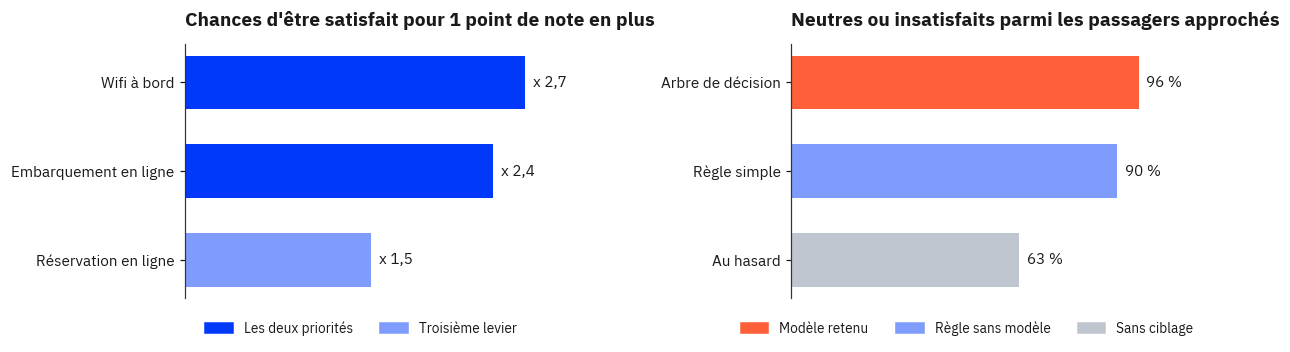

In [37]:
gr.synthese(odds, comparison);

### 10.2 Partie 1 du rapport : les données

#### Figure 1 – Part de chaque classe et origine des passagers neutres ou insatisfaits

- *D'où viennent les données* : section 1.2 (tableau `mix`) : répartition des répondants par classe, hypothèse de trafic réel (`CLASS_MIX_REEL`) et part des neutres ou insatisfaits après redressement.
- *Ce qu'il montre* : la Business est sur-représentée dans l'enquête ; une fois remise à sa place réelle, l'Eco concentre 71 % des passagers neutres ou insatisfaits.
- *Rôle* : ce graphique **ne remplace pas** le graphique d'étude de la section 1.2 (`fig0_ecart_sondage.png`). Il reprend les mêmes résultats, sans nouveau calcul de modèle, sous une forme simplifiée : il sert à **vulgariser** la donnée pour une personne non technique, non formée à l'analyse de données (le directeur et son comité).

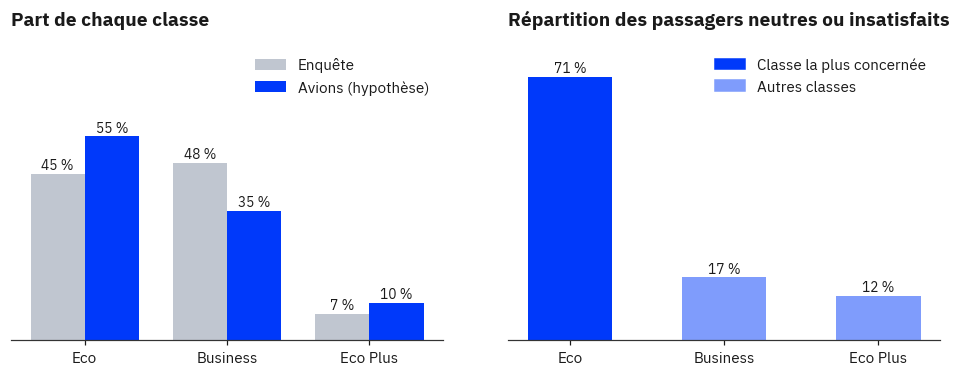

In [38]:
gr.classes(mix);

#### Figure 2 – Neutres ou insatisfaits selon le motif du voyage et la classe

- *D'où viennent les données* : données d'entraînement (`train`), redressées avec les poids de classe `W` ; mêmes segments que la section 2.3 (motif du voyage × classe).
- *Ce qu'il montre* : les voyageurs de loisirs en Eco ou Eco Plus sont presque tous neutres ou insatisfaits : c'est le premier groupe à traiter.
- *Rôle* : ce graphique **ne remplace pas** le graphique d'étude de la section 2.3. Il reprend les mêmes résultats, sans nouveau calcul de modèle, sous une forme simplifiée : il sert à **vulgariser** la donnée pour une personne non technique, non formée à l'analyse de données (le directeur et son comité).

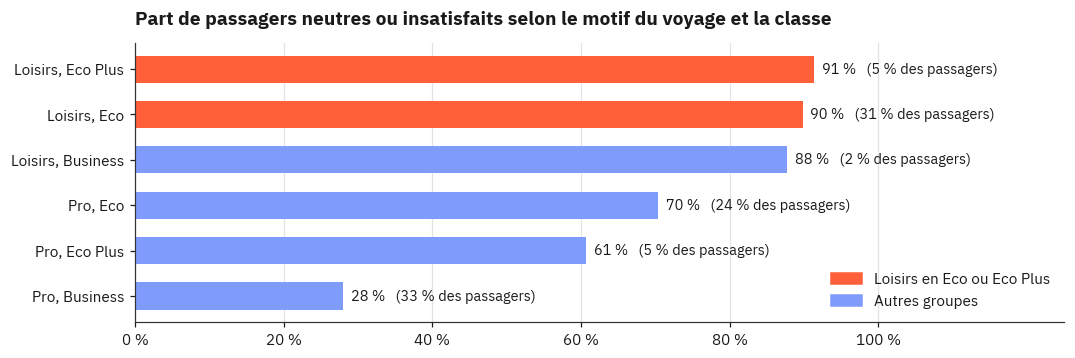

In [39]:
gr.motif_classe(train, y, W);

#### Figure 3 – Effet de l'âge et de la distance, une fois croisés

- *D'où viennent les données* : section 2.3 (tableau `age_cross` : âge × motif du voyage) et section 2.2 (tableau `by_cls` : distance × classe).
- *Ce qu'il montre* : l'âge et la distance semblent jouer, mais leur effet vient surtout du motif du voyage et de la classe.
- *Rôle* : ce graphique **ne remplace pas** le graphique d'étude de la section 2.2 (`fig_distance_detail.png`) et 2.3. Il reprend les mêmes résultats, sans nouveau calcul de modèle, sous une forme simplifiée : il sert à **vulgariser** la donnée pour une personne non technique, non formée à l'analyse de données (le directeur et son comité).

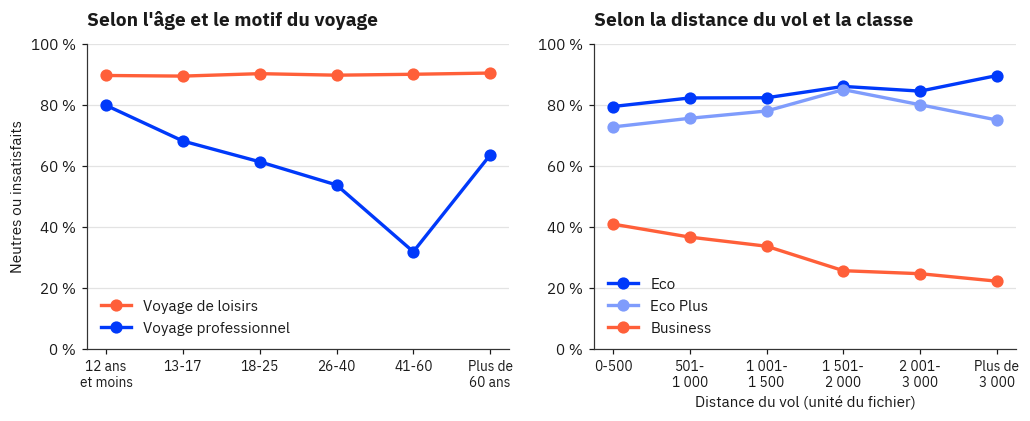

In [40]:
gr.age_distance(age_cross, by_cls);

### 10.3 Partie 2 du rapport : ce qui fait la satisfaction

#### Figure 4 – Force du lien entre la note d'un service et la satisfaction, par classe

- *D'où viennent les données* : section 3.1 (tableau `drivers`, colonnes `lien Eco`, `lien Business`, `lien Eco Plus` : corrélation de Spearman calculée dans chaque classe) ; les 8 services les plus liés, classés avec chaque classe à 1/3.
- *Ce qu'il montre* : l'embarquement en ligne compte dans les trois classes ; le wifi compte surtout en Eco et Eco Plus ; le confort cabine surtout en Business.
- *Rôle* : ce graphique **ne remplace pas** le graphique d'étude de la section 3.1 (`fig3_matrice_services.png`). Il reprend les mêmes résultats, sans nouveau calcul de modèle, sous une forme simplifiée : il sert à **vulgariser** la donnée pour une personne non technique, non formée à l'analyse de données (le directeur et son comité).

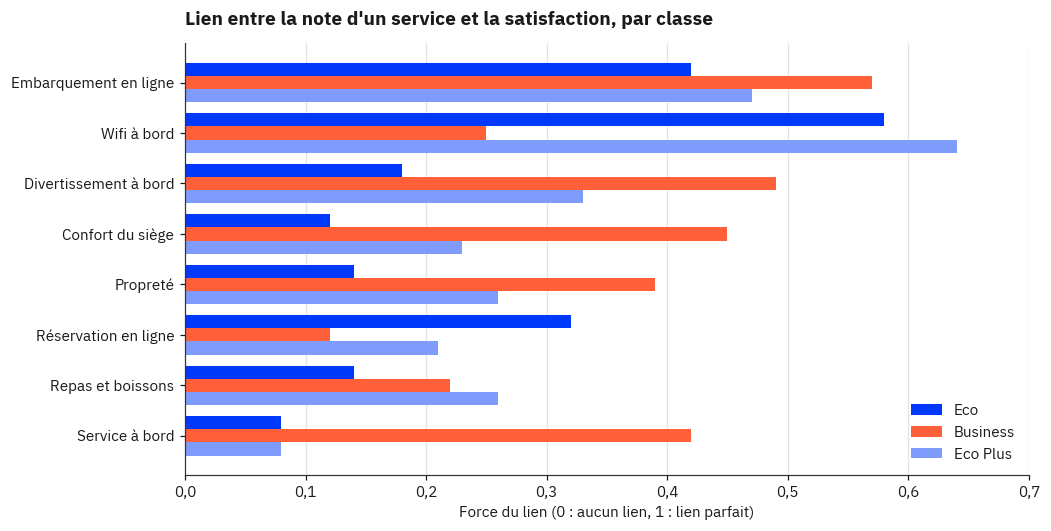

In [41]:
gr.lien_services(drivers);

#### Figure 5 – Effet d'un point de note en plus, à profil de passager égal

- *D'où viennent les données* : section 3.2 (tableau `odds` : rapports de chances de la régression logistique explicative, entraînée avec les poids de redressement).
- *Ce qu'il montre* : le wifi, l'embarquement en ligne et la réservation en ligne sont les seuls services à effet fort.
- *Rôle* : ce graphique **ne remplace pas** le graphique d'étude de la section 3.2. Il reprend les mêmes résultats, sans nouveau calcul de modèle, sous une forme simplifiée : il sert à **vulgariser** la donnée pour une personne non technique, non formée à l'analyse de données (le directeur et son comité).

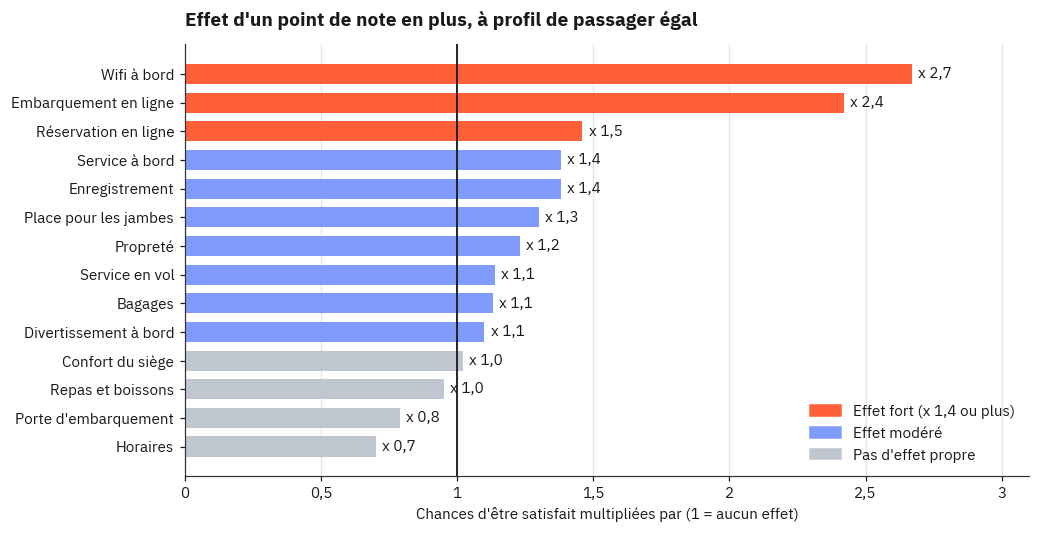

In [42]:
gr.effet_service(odds);

#### Figure 6 – Une note correcte (3) ne suffit pas

- *D'où viennent les données* : section 3.3 (tableau `kano`, colonnes `insat. si 3` et `insat. si 5`).
- *Ce qu'il montre* : passer d'une note de 3 à une note de 5 fait chuter la part de passagers neutres ou insatisfaits, surtout pour le wifi et l'embarquement en ligne.
- *Rôle* : ce graphique **ne remplace pas** le graphique d'étude de la section 3.3 (`fig4_ce_qui_rend_satisfait.png`). Il reprend les mêmes résultats, sans nouveau calcul de modèle, sous une forme simplifiée : il sert à **vulgariser** la donnée pour une personne non technique, non formée à l'analyse de données (le directeur et son comité).

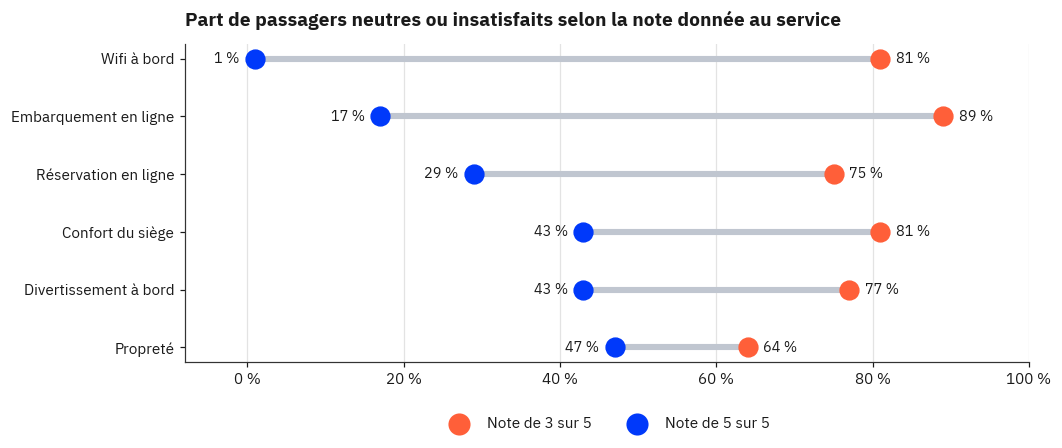

In [43]:
gr.note_3_vs_5(kano);

#### Figure 7 – Effet du retard à l'arrivée

- *D'où viennent les données* : section 2.4 (tableau `delays`, colonne `Arrival Delay in Minutes`, redressée).
- *Ce qu'il montre* : la part de passagers neutres ou insatisfaits monte jusqu'à 15 minutes de retard, puis se stabilise.
- *Rôle* : ce graphique **ne remplace pas** le graphique d'étude de la section 2.4 (`fig2_retards.png`). Il reprend les mêmes résultats, sans nouveau calcul de modèle, sous une forme simplifiée : il sert à **vulgariser** la donnée pour une personne non technique, non formée à l'analyse de données (le directeur et son comité).

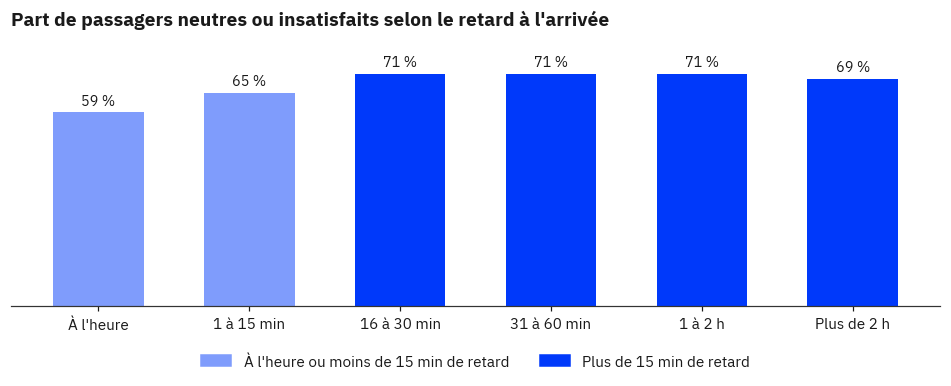

In [44]:
gr.retard(delays);

### 10.4 Partie 3 du rapport : repérer les passagers à l'arrivée

#### Figure 8 – L'arbre de décision retenu, en version simplifiée

- *D'où viennent les données* : section 4.5 (arbre de décision retenu) ; les pourcentages sont recalculés sur `train` avec les poids `W`, pour les trois questions principales de l'arbre.
- *Ce qu'il montre* : trois questions connues à l'atterrissage suffisent à désigner le groupe à approcher.
- *Rôle* : ce graphique **ne remplace pas** le graphique d'étude de la section 4.5 (`fig6_arbre.png` et tableau des règles). Il reprend les mêmes résultats, sans nouveau calcul de modèle, sous une forme simplifiée : il sert à **vulgariser** la donnée pour une personne non technique, non formée à l'analyse de données (le directeur et son comité).

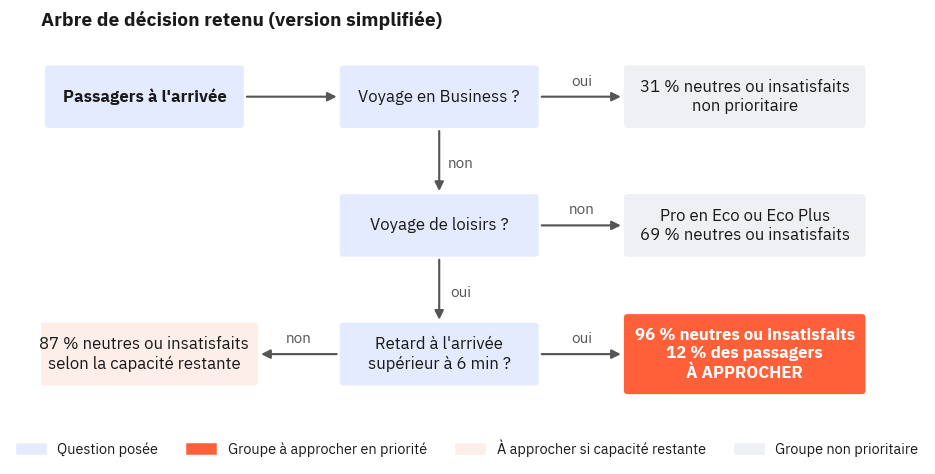

In [45]:
gr.arbre_simplifie(train, y, W);

#### Figure 9 – Ce sur quoi s'appuie le modèle le plus précis

- *D'où viennent les données* : section 4.5 b (série `importance` : perte d'AUC quand on brouille une variable), ramenée en % du total.
- *Ce qu'il montre* : le motif du voyage, la fidélité et la classe dominent, comme dans l'arbre retenu.
- *Rôle* : ce graphique **ne remplace pas** le graphique d'étude de la section 4.5 b (`fig7_importance.png`). Il reprend les mêmes résultats, sans nouveau calcul de modèle, sous une forme simplifiée : il sert à **vulgariser** la donnée pour une personne non technique, non formée à l'analyse de données (le directeur et son comité).

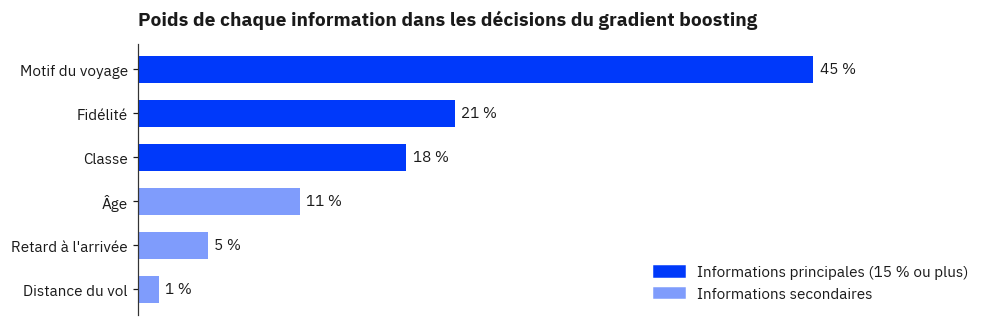

In [46]:
gr.importance_gb(importance);

#### Figure 10 – Comparaison des approches et coût des erreurs

- *D'où viennent les données* : section 4.3 (tableau `comparison` : précision dans le top 10 % et gain net, en validation croisée) et hypothèses économiques du directeur (`COST_APPROACH`, `GAIN_PER_TP`).
- *Ce qu'il montre* : sur 100 passagers approchés, combien sont réellement neutres ou insatisfaits, selon l'approche choisie.
- *Rôle* : ce graphique **ne remplace pas** le graphique d'étude de la section 4.4 et 4.6 (`fig5_precision_gain.png`). Il reprend les mêmes résultats, sans nouveau calcul de modèle, sous une forme simplifiée : il sert à **vulgariser** la donnée pour une personne non technique, non formée à l'analyse de données (le directeur et son comité).

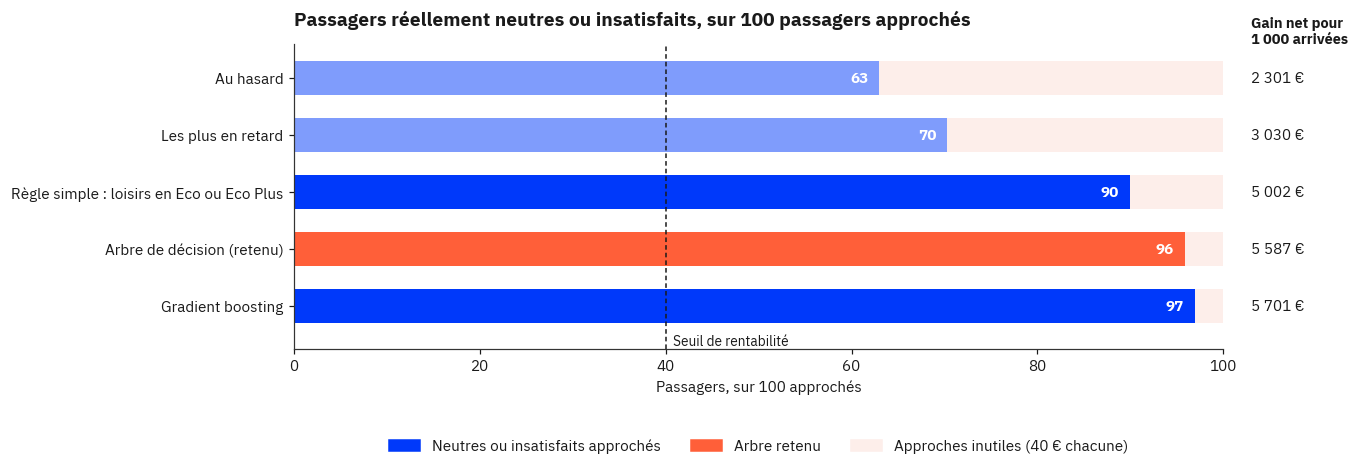

In [47]:
gr.comparaison(comparison, cost=COST_APPROACH, gain=GAIN_PER_TP);

#### Figure 11 – Résultat sur les passagers du mois suivant

- *D'où viennent les données* : section 6 (tableau `final` : validation croisée sur `train` et évaluation unique sur `test.csv`).
- *Ce qu'il montre* : le modèle obtient presque le même résultat sur des passagers qu'il n'avait jamais vus.
- *Rôle* : ce graphique **ne remplace pas** le graphique d'étude de la section 6. Il reprend les mêmes résultats, sans nouveau calcul de modèle, sous une forme simplifiée : il sert à **vulgariser** la donnée pour une personne non technique, non formée à l'analyse de données (le directeur et son comité).

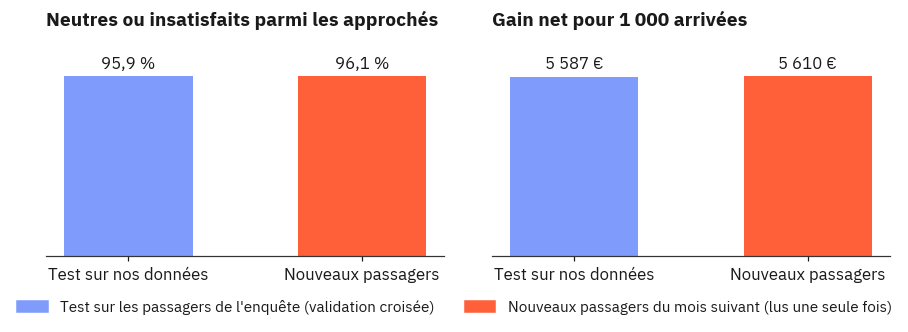

In [48]:
if RUN_FINAL_TEST:
    gr.test_final(final);
else:
    print("Figure 11 non produite : l'évaluation finale (section 6) n'a pas été lancée.")

### 10.5 Conclusion et annexe du rapport

#### Figure 12 – Les trois profils types

- *D'où viennent les données* : section 7.3 (tableau `profils` : part de neutres ou insatisfaits et part du trafic de chaque profil).
- *Ce qu'il montre* : seul P1 est à la fois presque toujours neutre ou insatisfait et proche de la capacité des équipes.
- *Rôle* : ce graphique **ne remplace pas** le graphique d'étude de la section 7.3. Il reprend les mêmes résultats, sans nouveau calcul de modèle, sous une forme simplifiée : il sert à **vulgariser** la donnée pour une personne non technique, non formée à l'analyse de données (le directeur et son comité).

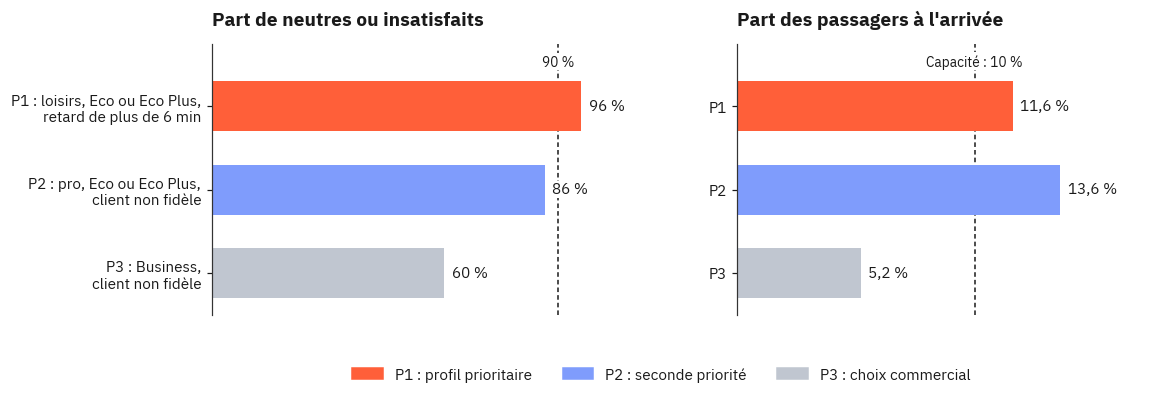

In [49]:
gr.profils_types(profils, capacity=CAPACITY);

#### Figure A – Robustesse au poids donné à chaque classe

- *D'où viennent les données* : section 4.8 (tableaux `ranks` : rang des services selon le mix de classes, et `mix_sensitivity` : précision des modèles).
- *Ce qu'il montre* : les priorités et la précision du modèle changent très peu, quelle que soit l'hypothèse sur la répartition des classes.
- *Rôle* : ce graphique **ne remplace pas** le graphique d'étude de la section 4.8 (`fig9_sensibilite_mix.png`). Il reprend les mêmes résultats, sans nouveau calcul de modèle, sous une forme simplifiée : il sert à **vulgariser** la donnée pour une personne non technique, non formée à l'analyse de données (le directeur et son comité).

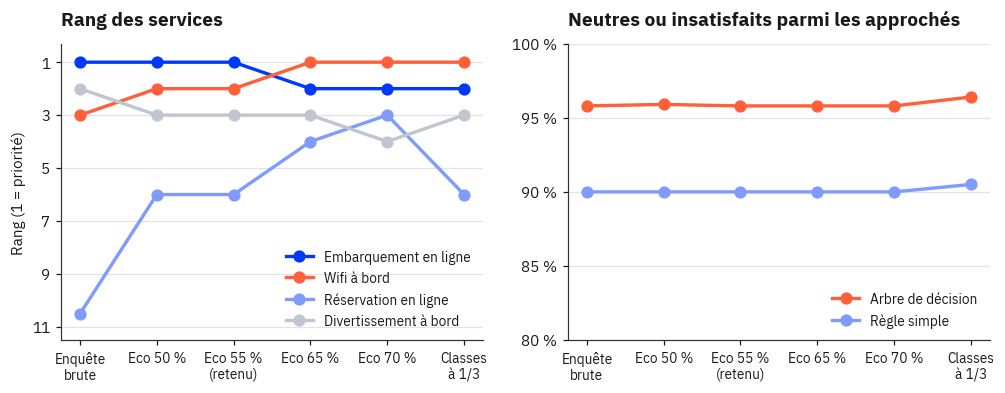

In [50]:
gr.robustesse(ranks, mix_sensitivity);